In [9]:
#changing so that scan_process_data is subtracting the background for everything!
import numpy as np
import h5py
import hdf5plugin
import matplotlib.pyplot as plt
from matplotlib import colors
from pathlib import Path
from collections import OrderedDict
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.animation import FuncAnimation
from collections import OrderedDict
from IPython.display import HTML,display
from scipy import ndimage
from scipy.ndimage import generic_filter
import re
from scipy.signal import find_peaks, peak_widths

In [10]:
save_path = Path(r'C:\Users\leeau\Dropbox\Stanford\Lindenberg Lab\2026_06_Lindenberg\analysis\BTO001_003')
waveform_path = Path(r'C:\Users\leeau\Dropbox\Stanford\Lindenberg Lab\2026_06_Lindenberg\ssrl_bto\post_run_gate_locations')
fine_pund_waveform_path = Path(r'C:\Users\leeau\Dropbox\Stanford\Lindenberg Lab\2026_06_Lindenberg\ssrl_bto\bto001\two_channel')
current_path = Path(r'C:\Users\leeau\Dropbox\Stanford\Lindenberg Lab\2026_06_Lindenberg\ssrl_bto\Yuejun_current_tracings')

In [11]:
def animate_diff_images(results, x_param='eta', roi=None, 
                       key_ranges=None, vmin=-1000, vmax=1000, cmap='bwr',
                       show_com=True, 
                       use_absolute_pixels=True, 
                       xlim=None, ylim=None,
                       interval=500, 
                       figsize=(8, 6), save_path=None,
                       display_animation=True,
                       log_scale = False,
                       linthresh = 1.0,
                       show_gate_images=False,
                       vmin_gate=None, vmax_gate=None,
                       cmap_gate='viridis'):
    """
    Animate difference images from process_scan_data results.
    
    Parameters:
    -----------
    results : dict
        Results dictionary from process_scan_data containing:
        - 'diff_stack': OrderedDict of difference images
        - 'eta_dict', 'delay_dict', 'voltage_dict': Parameter values
        - 'com_g1', 'com_g2': Centers of mass (if show_com=True)
        - 'g1_stack', 'g2_stack': Gate images (if show_gate_images=True)
    x_param : str, optional
        Parameter to animate over: 'eta', 'delay', 'voltage', or 'run'
        Default: 'eta'
    roi : list, optional
        ROI used in processing [row_start, row_end, col_start, col_end]
        Needed if show_com=True to get relative coordinates
    key_ranges : list of tuples, optional
        List of (min, max) bounds for x_param to create separate animations
        Example: [(11.0, 11.5), (11.6, 12.0)]
    vmin, vmax : float, optional
        Color scale limits for difference image (default: -1000, 1000)
    cmap : str, optional
        Colormap name for difference image (default: 'bwr')
    show_com : bool, optional
        Whether to show center of mass markers (default: True)
    interval : int, optional
        Time between frames in milliseconds (default: 500)
    figsize : tuple, optional
        Figure size - will be adjusted if show_gate_images=True (default: (8, 6))
    save_path : str, optional
        Base filename for saving animations (.mp4)
    display_animation : bool, optional
        If True, displays the animation in notebook (default: True)
    log_scale : bool, optional
        Use logarithmic color scale for difference image (default: False)
    linthresh : float, optional
        Threshold for symlognorm (default: 1.0)
    show_gate_images : bool, optional
        If True, shows G1 and G2 images below difference image (default: False)
    vmin_gate, vmax_gate : float, optional
        Color scale limits for gate images (auto-calculated if None)
    cmap_gate : str, optional
        Colormap for gate images (default: 'viridis')
    
    Returns:
    --------
    animation_widgets : list
        List of HTML animation widgets
    """
    import matplotlib.pyplot as plt
    import matplotlib.colors as colors
    from matplotlib.animation import FuncAnimation
    from IPython.display import HTML, display
    from pathlib import Path
    import numpy as np
    import imageio
    
    # Get the parameter dictionary
    if x_param == 'delay':
        param_dict = results['delay_dict']
        param_label = 'Delay'
        param_unit = ' μs'
    elif x_param == 'voltage':
        param_dict = results['voltage_dict']
        param_label = 'Voltage'
        param_unit = ' V'
    elif x_param == 'eta':
        param_dict = results['eta_dict']
        param_label = 'η'
        param_unit = '°'
    elif x_param == 'run':
        param_dict = {run: run for run in results['diff_stack'].keys()}
        param_label = 'Run'
        param_unit = ''
    else:
        raise ValueError("x_param must be 'delay', 'voltage', 'eta', or 'run'")
    
    # Ensure all parameter values are floats (except run which might be int)
    if x_param != 'run':
        param_dict = {k: float(v) if v is not None else None for k, v in param_dict.items()}
        # Remove None values
        param_dict = {k: v for k, v in param_dict.items() if v is not None}
    
    # Get difference images
    diff_stack = results['diff_stack']
    
    # Get gate images if needed
    if show_gate_images:
        g1_stack = results.get('g1_stack', {})
        g2_stack = results.get('g2_stack', {})
        
        if not g1_stack or not g2_stack:
            print("Warning: G1/G2 stacks not found in results. Disabling show_gate_images.")
            show_gate_images = False
    
    # Get moments for COM markers
    com_g1_dict = results.get('com_g1', {})
    com_g2_dict = results.get('com_g2', {})
    
    # Validate show_com
    if show_com and not roi:
        print("Warning: ROI needed for COM display. Disabling show_com.")
        show_com = False

    if use_absolute_pixels and not roi:
        print("Warning: ROI needed for absolute pixel positioning. Using relative pixels.")
        use_absolute_pixels = False

    # Get ROI offsets for absolute pixel positioning
    if roi is not None:
        roi_row_start, roi_row_end, roi_col_start, roi_col_end = roi
    else:
        roi_row_start = roi_col_start = 0
        
    animation_widgets = []
    
    # Set up key ranges
    if not key_ranges:
        valid_values = [v for v in param_dict.values() if v is not None]
        if valid_values:
            key_ranges = [(min(valid_values), max(valid_values))]
        else:
            print("No valid parameter values found!")
            return []
    
    for start, end in key_ranges:
        # Ensure start and end are floats (if not run mode)
        if x_param != 'run':
            start = float(start)
            end = float(end)
        
        # Filter runs in this parameter range
        subset_runs = [
            run for run, param_val in param_dict.items()
            if param_val is not None and start <= param_val <= end
        ]
        
        if not subset_runs:
            print(f"Skipping range ({start} to {end}): No matching runs found.")
            continue
        
        # Sort by parameter value
        subset_runs.sort(key=lambda run: param_dict[run])
        
        print(f"Creating animation for {x_param} range [{start}, {end}] with {len(subset_runs)} runs...")
        
        # Adjust figure size if showing gate images
        if show_gate_images:
            fig_height = figsize[1] * 3  # Double the height
            fig, axes = plt.subplots(3, 1, figsize=(figsize[0]*1.5, fig_height))
            ax_diff = axes[0]
            ax_g1 = axes[1]
            ax_g2 = axes[2]
            # Remove unused subplot
            # axes[0, 1].axis('off')
        else:
            fig, ax_diff = plt.subplots(figsize=figsize)
        
        # Initialize with first frame
        first_run = subset_runs[0]
        first_param = param_dict[first_run]
        first_image = diff_stack[first_run]

        # Set up normalization based on log_scale parameter
        if log_scale:
            norm = colors.SymLogNorm(linthresh=linthresh, vmin=vmin, vmax=vmax, base=10)
            scale_type = f"SymLog (linear ±{linthresh})"
        else:
            norm = colors.Normalize(vmin=vmin, vmax=vmax)
            scale_type = "Linear"
        
        print(f"  Using {scale_type} color scale")
        
        # Set up extent for absolute pixel positioning
        if use_absolute_pixels:
            num_rows, num_cols = first_image.shape
            extent = [roi_col_start, roi_col_start + num_cols, 
                     roi_row_start + num_rows, roi_row_start]
            im_diff = ax_diff.imshow(first_image, cmap=cmap, 
                          norm=norm,
                          extent=extent, origin='upper')
            pixel_label_h = 'Pixel (absolute horizontal)'
            pixel_label_v = 'Pixel (absolute vertical)'
        else:
            im_diff = ax_diff.imshow(first_image, cmap=cmap, 
                          norm=norm)
            pixel_label_h = 'Pixel (relative horizontal)'
            pixel_label_v = 'Pixel (relative vertical)'

        # Add colorbar for difference image
        if show_gate_images:
            cbar_diff = fig.colorbar(im_diff, ax=ax_diff, orientation='horizontal', pad=0.05)
        else:
            cbar_diff = fig.colorbar(im_diff, ax=ax_diff, orientation='horizontal', pad=0.05)
        
        cbar_label = 'Intensity Difference (G2 - G1)'
        if log_scale:
            cbar_label += f' [{scale_type}]'
        cbar_diff.set_label(cbar_label, fontsize=10)
        
        # Initialize COM markers if needed
        com1_marker_diff = None
        com2_marker_diff = None
        if show_com:
            com1_marker_diff, = ax_diff.plot([], [], 'go', markersize=8, 
                                  label='G1 COM', markeredgecolor='white', 
                                  markeredgewidth=1.5)
            com2_marker_diff, = ax_diff.plot([], [], 'mo', markersize=8, 
                                  label='G2 COM', markeredgecolor='white', 
                                  markeredgewidth=1.5)
            ax_diff.legend(loc='upper right', fontsize=10)
        
        # Set initial title
        if x_param == 'run':
            title_text = f"Difference: Run {first_run}"
        else:
            title_text = f"Difference: Run {first_run}, {param_label}: {first_param:.2f}{param_unit}"
        title_diff = ax_diff.set_title(title_text, fontsize=14)
        
        ax_diff.set_xlabel(pixel_label_h, fontsize=12)
        ax_diff.set_ylabel(pixel_label_v, fontsize=12)

        # Set axis limits if specified
        if xlim is not None:
            ax_diff.set_xlim(xlim)
        if ylim is not None:
            ax_diff.set_ylim(ylim)
        
        # Initialize gate images if needed
        im_g1, im_g2 = None, None
        title_g1, title_g2 = None, None
        com1_marker_g1, com2_marker_g1 = None, None
        com1_marker_g2, com2_marker_g2 = None, None
        cbar_g1, cbar_g2 = None, None
        
        if show_gate_images:
            first_g1 = g1_stack[first_run]
            first_g2 = g2_stack[first_run]
            
            # Auto-calculate gate image color limits if not provided
            if vmin_gate is None or vmax_gate is None:
                all_g1 = np.concatenate([g1_stack[run].flatten() for run in subset_runs])
                all_g2 = np.concatenate([g2_stack[run].flatten() for run in subset_runs])
                if vmin_gate is None:
                    vmin_gate = min(np.percentile(all_g1, 1), np.percentile(all_g2, 1))
                if vmax_gate is None:
                    vmax_gate = max(np.percentile(all_g1, 99), np.percentile(all_g2, 99))

            from matplotlib.ticker import LogFormatterSciNotation
            norm_gate = colors.LogNorm(vmin=vmin_gate, vmax=vmax_gate)
            
            # Setup G1 image
            if use_absolute_pixels:
                im_g1 = ax_g1.imshow(first_g1, cmap=cmap_gate, norm=norm_gate,
                                    extent=extent, origin='upper')
            else:
                im_g1 = ax_g1.imshow(first_g1, cmap=cmap_gate, norm=norm_gate)
            
            cbar_g1 = fig.colorbar(im_g1, ax=ax_g1, orientation='horizontal', pad=0.05, format = LogFormatterSciNotation())
            cbar_g1.set_label('G1 Intensity [Log Scale]', fontsize=10)
            
            if show_com:
                com1_marker_g1, = ax_g1.plot([], [], 'go', markersize=8, 
                                      label='G1 COM', markeredgecolor='white', 
                                      markeredgewidth=1.5)
                com2_marker_g1, = ax_g1.plot([], [], 'mo', markersize=8, 
                                      label='G2 COM', markeredgecolor='white', 
                                      markeredgewidth=1.5)
                ax_g1.legend(loc='upper right', fontsize=10)
            
            if x_param == 'run':
                title_g1 = ax_g1.set_title(f"G1: Run {first_run}", fontsize=14)
            else:
                title_g1 = ax_g1.set_title(f"G1: Run {first_run}, {param_label}: {first_param:.2f}{param_unit}", fontsize=14)
            
            ax_g1.set_xlabel(pixel_label_h, fontsize=12)
            ax_g1.set_ylabel(pixel_label_v, fontsize=12)
            
            if xlim is not None:
                ax_g1.set_xlim(xlim)
            if ylim is not None:
                ax_g1.set_ylim(ylim)
            
            # Setup G2 image
            if use_absolute_pixels:
                im_g2 = ax_g2.imshow(first_g2, cmap=cmap_gate, norm=norm_gate,
                                    extent=extent, origin='upper')
            else:
                im_g2 = ax_g2.imshow(first_g2, cmap=cmap_gate, norm=norm_gate)
            
            cbar_g2 = fig.colorbar(im_g2, ax=ax_g2, orientation='horizontal', pad=0.05, format = LogFormatterSciNotation())
            cbar_g2.set_label('G2 Intensity [Log Scale]', fontsize=10)
            
            if show_com:
                com1_marker_g2, = ax_g2.plot([], [], 'go', markersize=8, 
                                      label='G1 COM', markeredgecolor='white', 
                                      markeredgewidth=1.5)
                com2_marker_g2, = ax_g2.plot([], [], 'mo', markersize=8, 
                                      label='G2 COM', markeredgecolor='white', 
                                      markeredgewidth=1.5)
                ax_g2.legend(loc='upper right', fontsize=10)
            
            if x_param == 'run':
                title_g2 = ax_g2.set_title(f"G2: Run {first_run}", fontsize=14)
            else:
                title_g2 = ax_g2.set_title(f"G2: Run {first_run}, {param_label}: {first_param:.2f}{param_unit}", fontsize=14)
            
            ax_g2.set_xlabel(pixel_label_h, fontsize=12)
            ax_g2.set_ylabel(pixel_label_v, fontsize=12)
            
            if xlim is not None:
                ax_g2.set_xlim(xlim)
            if ylim is not None:
                ax_g2.set_ylim(ylim)
        
        plt.tight_layout()
        
        # Save if requested
        if save_path:
            path = Path(save_path)
            start_str = str(start).replace('.', '_')
            end_str = str(end).replace('.', '_')
            
            # Ensure .mp4 extension
            if path.suffix.lower() != '.mp4':
                path = path.with_suffix('.mp4')
            
            subset_path = path.parent / f"{path.stem}_{x_param}_{start_str}_to_{end_str}.mp4"
            fps = int(1000 / interval)
            
            print(f"Saving {x_param} range [{start}, {end}] to {subset_path.name}...")
            print(f"  Total frames to save: {len(subset_runs)}")
            
            # Get canvas size
            canvas_width, canvas_height = fig.canvas.get_width_height()
            
            # Create video writer
            writer = imageio.get_writer(subset_path, fps=fps, codec='libx264', 
                                       quality=8, pixelformat='yuv420p',
                                       macro_block_size=1)
            
            import time
            
            # Render each frame and write to video
            for frame_idx in range(len(subset_runs)):
                run = subset_runs[frame_idx]
                diff_image = diff_stack[run]
                param_value = param_dict[run]
                
                # Update difference image
                im_diff.set_data(diff_image)
                
                # Update title
                if x_param == 'run':
                    title_diff.set_text(f"Difference: Run {run}")
                else:
                    title_diff.set_text(f"Difference: Run {run}, {param_label}: {param_value:.2f}{param_unit}")
                
                # Update COM markers on difference image
                if show_com and com1_marker_diff is not None and run in com_g1_dict and run in com_g2_dict:
                    com1_abs = com_g1_dict[run]
                    com2_abs = com_g2_dict[run]
                    
                    if use_absolute_pixels:
                        com1_col = com1_abs[1]
                        com1_row = com1_abs[0]
                        com2_col = com2_abs[1]
                        com2_row = com2_abs[0]
                    else:
                        com1_row = com1_abs[0] - roi_row_start
                        com1_col = com1_abs[1] - roi_col_start
                        com2_row = com2_abs[0] - roi_row_start
                        com2_col = com2_abs[1] - roi_col_start
                    
                    com1_marker_diff.set_data([com1_col], [com1_row])
                    com2_marker_diff.set_data([com2_col], [com2_row])
                
                # Update gate images if shown
                if show_gate_images:
                    g1_image = g1_stack[run]
                    g2_image = g2_stack[run]
                    
                    im_g1.set_data(g1_image)
                    im_g2.set_data(g2_image)
                    
                    if x_param == 'run':
                        title_g1.set_text(f"G1: Run {run}")
                        title_g2.set_text(f"G2: Run {run}")
                    else:
                        title_g1.set_text(f"G1: Run {run}, {param_label}: {param_value:.2f}{param_unit}")
                        title_g2.set_text(f"G2: Run {run}, {param_label}: {param_value:.2f}{param_unit}")
                    
                    # Update COM markers on gate images
                    if show_com and run in com_g1_dict and run in com_g2_dict:
                        com1_marker_g1.set_data([com1_col], [com1_row])
                        com2_marker_g1.set_data([com2_col], [com2_row])
                        com1_marker_g2.set_data([com1_col], [com1_row])
                        com2_marker_g2.set_data([com2_col], [com2_row])
                
                # Force a full redraw with small delay
                fig.canvas.draw()
                fig.canvas.flush_events()
                time.sleep(0.05)  # 50ms delay to ensure rendering completes
                
                # Convert canvas to RGBA array
                frame = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
                frame = frame.reshape(canvas_height, canvas_width, 4)
                
                # Convert RGBA to RGB
                frame_rgb = frame[:, :, :3].copy()
                
                # Write frame (with buffer frames at start and end)
                if frame_idx == 0:
                    # Write first frame 3 times as buffer
                    for _ in range(3):
                        writer.append_data(frame_rgb)
                    print(f"  Frame {frame_idx + 1}/{len(subset_runs)} - Run {run}, {param_label}: {param_value:.2f}{param_unit} [START BUFFER]")
                elif frame_idx == len(subset_runs) - 1:
                    # Write last frame 3 times as buffer
                    writer.append_data(frame_rgb)
                    for _ in range(3):
                        writer.append_data(frame_rgb)
                    print(f"  Frame {frame_idx + 1}/{len(subset_runs)} - Run {run}, {param_label}: {param_value:.2f}{param_unit} [END BUFFER]")
                else:
                    writer.append_data(frame_rgb)
                    if (frame_idx + 1) % 5 == 0:
                        print(f"  Frame {frame_idx + 1}/{len(subset_runs)} - Run {run}, {param_label}: {param_value:.2f}{param_unit}")
            
            writer.close()
            print(f"Saved to {subset_path}")
            print(f"  Total frames written: {len(subset_runs) + 4} (including buffers)")
        
        plt.close(fig)
        
        # Display animation if requested
        if display_animation:
            # Recreate animation for display
            if show_gate_images:
                fig_display, axes_display = plt.subplots(3, 1, figsize=(figsize[0], figsize[1]*3))
                ax_diff_d = axes_display[0]
                ax_g1_d = axes_display[1]
                ax_g2_d = axes_display[2]
            else:
                fig_display, ax_diff_d = plt.subplots(figsize=figsize)
            
            # Re-setup the difference plot
            if use_absolute_pixels:
                num_rows, num_cols = first_image.shape
                extent = [roi_col_start, roi_col_start + num_cols, 
                         roi_row_start + num_rows, roi_row_start]
                im_diff_d = ax_diff_d.imshow(first_image, cmap=cmap, 
                              norm=norm, extent=extent, origin='upper')
            else:
                im_diff_d = ax_diff_d.imshow(first_image, cmap=cmap, norm=norm)
            
            cbar_diff_d = fig_display.colorbar(im_diff_d, ax=ax_diff_d, 
                                               orientation='horizontal', pad=0.05)
            cbar_diff_d.set_label(cbar_label, fontsize=10)
            
            com1_marker_diff_d = None
            com2_marker_diff_d = None
            if show_com:
                com1_marker_diff_d, = ax_diff_d.plot([], [], 'go', markersize=8, 
                                      label='G1 COM', markeredgecolor='white', 
                                      markeredgewidth=1.5)
                com2_marker_diff_d, = ax_diff_d.plot([], [], 'mo', markersize=8, 
                                      label='G2 COM', markeredgecolor='white', 
                                      markeredgewidth=1.5)
                ax_diff_d.legend(loc='upper right', fontsize=10)
            
            title_diff_d = ax_diff_d.set_title(title_text, fontsize=14)
            ax_diff_d.set_xlabel(pixel_label_h, fontsize=12)
            ax_diff_d.set_ylabel(pixel_label_v, fontsize=12)
            
            if xlim is not None:
                ax_diff_d.set_xlim(xlim)
            if ylim is not None:
                ax_diff_d.set_ylim(ylim)
            
            # Setup gate images for display
            im_g1_d, im_g2_d = None, None
            title_g1_d, title_g2_d = None, None
            com1_marker_g1_d, com2_marker_g1_d = None, None
            com1_marker_g2_d, com2_marker_g2_d = None, None
            
            if show_gate_images:
                first_g1 = g1_stack[first_run]
                first_g2 = g2_stack[first_run]

                # from matplotlib.ticker import LogFormatterSciNotation
                norm_gate = colors.LogNorm(vmin=vmin_gate, vmax=vmax_gate)
                
                # Setup G1 display
                if use_absolute_pixels:
                    im_g1_d = ax_g1_d.imshow(first_g1, cmap=cmap_gate, norm=norm_gate,
                                        extent=extent, origin='upper')
                else:
                    im_g1_d = ax_g1_d.imshow(first_g1, cmap=cmap_gate, norm=norm_gate)
                
                cbar_g1_d = fig_display.colorbar(im_g1_d, ax=ax_g1_d, orientation='horizontal', pad=0.05, format = LogFormatterSciNotation())
                cbar_g1_d.set_label('G1 Intensity [Log Scale]', fontsize=10)
                
                if show_com:
                    com1_marker_g1_d, = ax_g1_d.plot([], [], 'go', markersize=8, 
                                          label='G1 COM', markeredgecolor='white', 
                                          markeredgewidth=1.5)
                    com2_marker_g1_d, = ax_g1_d.plot([], [], 'mo', markersize=8, 
                                          label='G2 COM', markeredgecolor='white', 
                                          markeredgewidth=1.5)
                    ax_g1_d.legend(loc='upper right', fontsize=10)
                
                if x_param == 'run':
                    title_g1_d = ax_g1_d.set_title(f"G1: Run {first_run}", fontsize=14)
                else:
                    title_g1_d = ax_g1_d.set_title(f"G1: Run {first_run}, {param_label}: {first_param:.2f}{param_unit}", fontsize=14)
                
                ax_g1_d.set_xlabel(pixel_label_h, fontsize=12)
                ax_g1_d.set_ylabel(pixel_label_v, fontsize=12)
                
                if xlim is not None:
                    ax_g1_d.set_xlim(xlim)
                if ylim is not None:
                    ax_g1_d.set_ylim(ylim)
                
                # Setup G2 display
                if use_absolute_pixels:
                    im_g2_d = ax_g2_d.imshow(first_g2, cmap=cmap_gate, norm=norm_gate,
                                        extent=extent, origin='upper')
                else:
                    im_g2_d = ax_g2_d.imshow(first_g2, cmap=cmap_gate, norm=norm_gate)
                
                cbar_g2_d = fig_display.colorbar(im_g2_d, ax=ax_g2_d, orientation='horizontal', pad=0.05, format = LogFormatterSciNotation())
                cbar_g2_d.set_label('G2 Intensity [Log Scale]', fontsize=10)
                
                if show_com:
                    com1_marker_g2_d, = ax_g2_d.plot([], [], 'go', markersize=8, 
                                          label='G1 COM', markeredgecolor='white', 
                                          markeredgewidth=1.5)
                    com2_marker_g2_d, = ax_g2_d.plot([], [], 'mo', markersize=8, 
                                          label='G2 COM', markeredgecolor='white', 
                                          markeredgewidth=1.5)
                    ax_g2_d.legend(loc='upper right', fontsize=10)
                
                if x_param == 'run':
                    title_g2_d = ax_g2_d.set_title(f"G2: Run {first_run}", fontsize=14)
                else:
                    title_g2_d = ax_g2_d.set_title(f"G2: Run {first_run}, {param_label}: {first_param:.2f}{param_unit}", fontsize=14)
                
                ax_g2_d.set_xlabel(pixel_label_h, fontsize=12)
                ax_g2_d.set_ylabel(pixel_label_v, fontsize=12)
                
                if xlim is not None:
                    ax_g2_d.set_xlim(xlim)
                if ylim is not None:
                    ax_g2_d.set_ylim(ylim)
            
            plt.tight_layout()
            
            def update_display(frame_idx):
                run = subset_runs[frame_idx]
                diff_image = diff_stack[run]
                param_value = param_dict[run]
                
                # Update difference image
                im_diff_d.set_data(diff_image)
                
                if x_param == 'run':
                    title_diff_d.set_text(f"Difference: Run {run}")
                else:
                    title_diff_d.set_text(f"Difference: Run {run}, {param_label}: {param_value:.2f}{param_unit}")
                
                artists = [im_diff_d, title_diff_d]
                
                # Update COM markers on difference image
                if show_com and com1_marker_diff_d is not None and run in com_g1_dict and run in com_g2_dict:
                    com1_abs = com_g1_dict[run]
                    com2_abs = com_g2_dict[run]
                    
                    if use_absolute_pixels:
                        com1_col = com1_abs[1]
                        com1_row = com1_abs[0]
                        com2_col = com2_abs[1]
                        com2_row = com2_abs[0]
                    else:
                        com1_row = com1_abs[0] - roi_row_start
                        com1_col = com1_abs[1] - roi_col_start
                        com2_row = com2_abs[0] - roi_row_start
                        com2_col = com2_abs[1] - roi_col_start
                    
                    com1_marker_diff_d.set_data([com1_col], [com1_row])
                    com2_marker_diff_d.set_data([com2_col], [com2_row])
                    
                    artists.extend([com1_marker_diff_d, com2_marker_diff_d])
                
                # Update gate images if shown
                if show_gate_images:
                    g1_image = g1_stack[run]
                    g2_image = g2_stack[run]
                    
                    im_g1_d.set_data(g1_image)
                    im_g2_d.set_data(g2_image)
                    
                    if x_param == 'run':
                        title_g1_d.set_text(f"G1: Run {run}")
                        title_g2_d.set_text(f"G2: Run {run}")
                    else:
                        title_g1_d.set_text(f"G1: Run {run}, {param_label}: {param_value:.2f}{param_unit}")
                        title_g2_d.set_text(f"G2: Run {run}, {param_label}: {param_value:.2f}{param_unit}")
                    
                    artists.extend([im_g1_d, title_g1_d, im_g2_d, title_g2_d])
                    
                    # Update COM markers on gate images
                    if show_com and run in com_g1_dict and run in com_g2_dict:
                        com1_marker_g1_d.set_data([com1_col], [com1_row])
                        com2_marker_g1_d.set_data([com2_col], [com2_row])
                        com1_marker_g2_d.set_data([com1_col], [com1_row])
                        com2_marker_g2_d.set_data([com2_col], [com2_row])
                        
                        artists.extend([com1_marker_g1_d, com2_marker_g1_d, 
                                      com1_marker_g2_d, com2_marker_g2_d])
                
                return artists
            
            ani_display = FuncAnimation(fig_display, update_display, 
                                       frames=len(subset_runs), 
                                       interval=interval, blit=True)
            
            html_player = HTML(ani_display.to_jshtml())
            print(f"\n=== Animation {param_label} Range: {start} to {end} ===")
            display(html_player)
            animation_widgets.append(html_player)
            
            plt.close(fig_display)
        
    return animation_widgets

In [12]:
#Defining functions to use throughout the notebook.
def calc_moments(img, roi, lineout_range=None, lineout_axis=0):
    """
    Calculate image moments including COM, variance, skewness, and kurtosis.
    
    Parameters:
    -----------
    img : ndarray
        2D image array
    roi : tuple
        Region of interest as (row_start, row_end, col_start, col_end)
    lineout_range : tuple, optional
        Range within ROI for lineout as (start, end) in pixels relative to ROI origin
        If provided, only this range is used for moment calculations
    lineout_axis : int, optional
        Axis along which to apply lineout_range (0=rows, 1=cols). Default is 0.
    
    Returns:
    --------
    moments : dict
        Dictionary containing calculated moments
    """
    
    # Extract signal region, this is the entire ROI
    img_signal = img[roi[0]:roi[1], roi[2]:roi[3]]
        
    # Replace NaNs with zeros (background already subtracted upstream)
    img_clean = np.nan_to_num(img_signal, nan=0)
    
    # Apply lineout range if specified
    if lineout_range is not None:
        if lineout_axis == 0:  # Restrict rows
            # Use only specified row range within ROI
            img_clean = img_clean[lineout_range[0]:lineout_range[1], :]
            # Create coordinate grids for lineout region
            rows_grid, col_grid = np.mgrid[
                roi[0] + lineout_range[0]:roi[0] + lineout_range[1], 
                roi[2]:roi[3]
            ]
        else:  # Restrict columns
            # Use only specified column range within ROI
            img_clean = img_clean[:, lineout_range[0]:lineout_range[1]]
            # Create coordinate grids for lineout region
            rows_grid, col_grid = np.mgrid[
                roi[0]:roi[1],
                roi[2] + lineout_range[0]:roi[2] + lineout_range[1]
            ]
    else:
        # Create coordinate grids for full ROI
        rows_grid, col_grid = np.mgrid[roi[0]:roi[1], roi[2]:roi[3]]
    
    # Flatten arrays
    img_flat = img_clean.flatten()
    rows_flat = rows_grid.flatten()
    cols_flat = col_grid.flatten()
    total_intensity = np.sum(img_flat)
    
    if total_intensity <= 0:
        return {
            'tot_int': np.array([0]),
            'com_rel': np.array([np.nan, np.nan]),
            'com_abs': np.array([np.nan, np.nan]),
            'variance': np.array([np.nan, np.nan]),
            'skewness': np.array([np.nan, np.nan]),
            'kurtosis': np.array([np.nan, np.nan])
        }
    
    # Calculate moments
    com_row = np.sum(img_flat * rows_flat) / total_intensity
    com_col = np.sum(img_flat * cols_flat) / total_intensity
    var_row = np.sum(img_flat * (rows_flat - com_row)**2) / total_intensity
    var_col = np.sum(img_flat * (cols_flat - com_col)**2) / total_intensity
    
    # Avoid division by zero for skewness and kurtosis
    if var_row > 0:
        skew_row = (np.sum(img_flat * (rows_flat - com_row)**3) / 
                   (total_intensity * var_row**1.5))
        kurt_row = (np.sum(img_flat * (rows_flat - com_row)**4) / 
                   (total_intensity * var_row**2))
    else:
        skew_row = np.nan
        kurt_row = np.nan
        
    if var_col > 0:
        skew_col = (np.sum(img_flat * (cols_flat - com_col)**3) / 
                   (total_intensity * var_col**1.5))
        kurt_col = (np.sum(img_flat * (cols_flat - com_col)**4) / 
                   (total_intensity * var_col**2))
    else:
        skew_col = np.nan
        kurt_col = np.nan

    moments = {
        'tot_int': np.array([total_intensity]),
        'com_rel': np.array([com_row - roi[0], com_col - roi[2]]),  # Relative to ROI
        'com_abs': np.array([com_row, com_col]),  # Absolute position
        'variance': np.array([var_row, var_col]),
        'skewness': np.array([skew_row, skew_col]),
        'kurtosis': np.array([kurt_row, kurt_col])
    }
    
    return moments

def print_moments(moments_g1, moments_g2=None, keys=None, run=None, precision=2, labels=None, show_diff=True):
    """
    Print selected moments from calc_moments output.
    
    Parameters:
    -----------
    moments_g1 : dict
        Moments dictionary from calc_moments for Gate 1
    moments_g2 : dict, optional
        Moments dictionary from calc_moments for Gate 2
    keys : list of str, optional
        List of keys to print from moments dict. 
        If None, prints all available keys.
        Available: 'background', 'total_intensity', 'com', 'com_rel', 
                   'variance', 'skewness', 'kurtosis'
    run : int or str, optional
        Run number to include in header
    precision : int, optional
        Number of decimal places for floating point values (default: 2)
    labels : dict, optional
        Custom labels for gates, e.g., {'g1': 'Gate 1', 'g2': 'Gate 2'}
    show_diff : bool, optional
        Whether to show G2-G1 difference (default: True)
    """
    # Default labels
    if labels is None:
        labels = {'g1': 'G1', 'g2': 'G2'}
    
    # If no keys specified, use all available keys
    if keys is None:
        keys = list(moments_g1.keys())
    
    # Print header
    if run is not None:
        print(f"Run {run}:")
    
    # Print each key
    for key in keys:
        # Format the key name for display
        key_display = key.replace('_', ' ').title()
        
        # Print G1 value
        if key in moments_g1:
            value_g1 = moments_g1[key]
            if isinstance(value_g1, (list, np.ndarray)):
                formatted_g1 = f"[{', '.join([f'{v:.{precision}f}' for v in value_g1])}]"
            elif isinstance(value_g1, (int, float, np.number)):
                formatted_g1 = f"{value_g1:.{precision}f}"
            else:
                formatted_g1 = str(value_g1)
            
            print(f"  {labels['g1']} {key_display}: {formatted_g1}")
        
        # Print G2 value if provided
        if moments_g2 is not None and key in moments_g2:
            value_g2 = moments_g2[key]
            if isinstance(value_g2, (list, np.ndarray)):
                formatted_g2 = f"[{', '.join([f'{v:.{precision}f}' for v in value_g2])}]"
            elif isinstance(value_g2, (int, float, np.number)):
                formatted_g2 = f"{value_g2:.{precision}f}"
            else:
                formatted_g2 = str(value_g2)
            
            print(f"  {labels['g2']} {key_display}: {formatted_g2}")

            # Print difference (G2 - G1) if requested
            if show_diff and key in moments_g1:
                try:
                    if isinstance(value_g2, (list, np.ndarray)):
                        diff = np.array(value_g2) - np.array(value_g1)
                        formatted_diff = f"[{', '.join([f'{v:.{precision}f}' for v in diff])}]"
                    elif isinstance(value_g2, (int, float, np.number)):
                        diff = value_g2 - value_g1
                        formatted_diff = f"{diff:.{precision}f}"
                    else:
                        formatted_diff = None
                    
                    if formatted_diff is not None:
                        print(f"  {labels['g2']} - {labels['g1']} {key_display}: {formatted_diff}")
                except (TypeError, ValueError):
                    # Skip difference if subtraction not possible
                    pass

def visualize_rois(data, signal_roi, background_roi):
    """Show signal and background ROIs on image"""
    from matplotlib.patches import Rectangle
    
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(data, norm=colors.LogNorm(vmin=1, vmax=1e4))
    
    # Signal ROI (red)
    signal_rect = Rectangle(
        (signal_roi[2], signal_roi[0]), 
        signal_roi[3]-signal_roi[2], 
        signal_roi[1]-signal_roi[0],
        linewidth=2, edgecolor='r', facecolor='none', label='Signal ROI'
    )
    ax.add_patch(signal_rect)
    
    # Background ROI (green)
    bg_rect = Rectangle(
        (background_roi[2], background_roi[0]), 
        background_roi[3]-background_roi[2], 
        background_roi[1]-background_roi[0],
        linewidth=2, edgecolor='g', facecolor='none', label='Background ROI'
    )
    ax.add_patch(bg_rect)
    
    ax.legend()
    ax.set_title('ROI Selection')
    plt.show()

def remove_hot_pixels(data, simple_threshold=4e5, check_spacing=1):
    """
    Remove hot pixels by checking sparse grid of pixels
    Much faster for large images
    
    Parameters:
    -----------
    data : 2D array
    simple_threshold : float
        Absolute threshold for hot pixels
    check_spacing : int
        Check every Nth pixel (e.g., 5 = check every 5th pixel)
    """
    from scipy.ndimage import median_filter
    
    data_clean = data.copy().astype(float)
    
    # Method 1: Simple absolute threshold (applied to all pixels)
    data_clean = np.where(data_clean > simple_threshold, np.nan, data_clean)
    
    # Method 2: Sparse neighborhood check
    # Only check pixels on a sparse grid
    rows, cols = data_clean.shape
    
    # Create median filtered version (3x3 neighborhood)
    median_filtered = median_filter(np.nan_to_num(data_clean, nan=0), size=3)
    
    # Only check every Nth pixel
    for i in range(0, rows, check_spacing):
        for j in range(0, cols, check_spacing):
            pixel_val = data_clean[i, j]
            median_val = median_filtered[i, j]
            
            # If pixel is much brighter than its neighborhood median
            if not np.isnan(pixel_val) and median_val > 0:
                if pixel_val > 10 * median_val:  # 10x threshold
                    data_clean[i, j] = np.nan
    
    return data_clean


def parse_filename(file, fields=['run', 'voltage', 'delay', 'eta']):
    """
    Parse specified fields from filename
    
    Parameters:
    -----------
    file : Path object
    fields : list of str
        Which fields to parse: 'run', 'voltage', 'delay', 'eta'
    
    Returns:
    --------
    dict with requested fields (only includes fields found in filename)
    """
    import re
    result = {}
    filename = file.stem
    
    #print(f"DEBUG: Parsing filename: {filename}")  # DEBUG
    
    if 'run' in fields:
        match = re.search(r'run(\d+)', filename)
        if match:
            result['run'] = int(match.group(1))
            #print(f"DEBUG: Found run: {result['run']}")  # DEBUG
    
    if 'voltage' in fields:
        match = re.search(r'(\d+(?:p\d+)?m?V)', filename)
        if match:
            voltage = match.group(1).replace('V', '')
            voltage = voltage.replace('m', 'e-3').replace('p', '.')
            result['voltage'] = float(voltage) * 20
            #print(f"DEBUG: Found voltage: {result['voltage']}")  # DEBUG
    
    if 'delay' in fields:
        match = re.search(r'delay([\d.p]+)us', filename)
        #print(f"DEBUG: delay match object: {match}")  # DEBUG
        if match:
            result['delay'] = match.group(1).replace('p', '.')
            #print(f"DEBUG: Found delay: {result['delay']}")  # DEBUG
        else:
            print(f"DEBUG: delay NOT found in filename")  # DEBUG
        
    if 'eta' in fields:
        match = re.search(r'eta([\d.p]+)', filename)
        if match:
            result['eta'] = match.group(1).replace('p', '.')
            #print(f"DEBUG: Found eta: {result['eta']}")  # DEBUG
    
    return result

def plot_lineouts(lineout_1, lineout_2, moments_g1=None, moments_g2=None, run=None, voltage=None, delay=None, eta = None, 
                  figsize=(18, 4), show_com=True):
    """
    Plot two lineouts and their difference.
    
    Parameters:
    -----------
    lineout_1 : array-like
        First lineout data (Gate 1)
    lineout_2 : array-like
        Second lineout data (Gate 2)
    moments_g1 : dict, optional
        Dictionary containing 'com_rel' key for Gate 1 center of mass
    moments_g2 : dict, optional
        Dictionary containing 'com_rel' key for Gate 2 center of mass
    figsize : tuple, optional
        Figure size (default: (12, 4))
    show_com : bool, optional
        Whether to show COM vertical lines (default: True)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axes objects
    """
    import matplotlib.pyplot as plt
    import numpy as np
    
    fig, ax = plt.subplots(1, 3, figsize=figsize)
    
    # Left panel: both lineouts
    ax[0].plot(lineout_1, label='Gate 1')
    ax[0].plot(lineout_2, label='Gate 2')
    
    # Add vertical lines for centers of mass if requested
    if show_com and moments_g1 is not None and moments_g2 is not None:
        ax[0].axvline(x=moments_g1['com_rel'][1], color='tab:blue', 
                      linestyle='--', linewidth=1, label='G1 COM')
        ax[0].axvline(x=moments_g2['com_rel'][1], color='tab:orange', 
                      linestyle='--', linewidth=1, label='G2 COM')
    
    ax[0].legend()
    ax[0].set_xlabel('Pixel', fontsize=14)
    ax[0].set_ylabel('Summed Int', fontsize=14)
    ax[0].tick_params(axis='both', labelsize=14, length=6, width=2)
    
    # Middle panel: difference
    ax[1].plot(lineout_2 - lineout_1, label='On-Off')
    ax[1].set_xlabel('Pixel', fontsize=14)
    ax[1].set_ylabel('Summed Intensity Difference (G2-G1)', fontsize=14)
    ax[1].tick_params(axis='both', labelsize=14, length=8, width=2)

    # Right pannel: normalized difference
    ax[2].plot(((lineout_2 - lineout_1)/lineout_1))
    ax[2].set_xlabel('Pixel', fontsize=14)
    ax[2].set_ylabel('ΔI/I (G2-G1)/(G1)', fontsize=14)
    ax[2].tick_params(axis='both', labelsize=14, length=8, width=2)

    # Add title if parameters provided
    if run is not None or voltage is not None or delay is not None or eta is not None:
        title_parts = []
        if run is not None:
            title_parts.append(f'run: {run}')
        if voltage is not None:
            title_parts.append(f'Voltage: {voltage:.2f} V')
        if delay is not None:
            title_parts.append(f'Delay: {delay} μs')
        if eta is not None:
            title_parts.append(f'Eta: {eta}°')
        fig.suptitle(', '.join(title_parts))
    
    return fig, ax

def plot_diff_image(data, roi, moments_g1, moments_g2, run=None, voltage=None, delay=None, eta = None,
                    vmin=-300, vmax=300, cmap='bwr', figsize=None, show_com=True, 
                    log_scale=False, linthresh = 1.0, hlines=None, vlines=None):
    """
    Plot difference image between two gates with centers of mass.
    
    Parameters:
    -----------
    data : array-like
        Data array where data[0] is Gate 1 and data[1] is Gate 2
    roi : tuple or list
        Region of interest as (row_start, row_end, col_start, col_end)
    moments_g1 : dict
        Dictionary containing 'com_rel' key for Gate 1 center of mass
    moments_g2 : dict
        Dictionary containing 'com_rel' key for Gate 2 center of mass
    run : int or str, optional
        Run number for title
    voltage : float, optional
        Voltage value for title
    delay : float, optional
        Delay value for title
    vmin : float, optional
        Minimum value for colormap normalization (default: -300)
    vmax : float, optional
        Maximum value for colormap normalization (default: 300)
    cmap : str, optional
        Colormap name (default: 'bwr')
    figsize : tuple, optional
        Figure size (default: None, uses matplotlib default)
    show_com : bool, optional
        Whether to show COM markers (default: True)
    log_scale : bool, optional
        If True, use symmetric logarithmic color scale (default: False)
        Uses SymLogNorm which is linear near zero and logarithmic elsewhere
    linthresh : float, optional
        For log_scale=True: threshold for SymLogNorm defining the linear region
        around zero. Values between -linthresh and +linthresh are scaled linearly.
        (default: 1.0)
    hlines : list or array-like, optional
        Y-values at which to draw horizontal green lines (default: None)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axes objects
    """
    import matplotlib.pyplot as plt
    import matplotlib.colors as colors
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Calculate difference image
    diff_image = data[1][roi[0]:roi[1], roi[2]:roi[3]] - data[0][roi[0]:roi[1], roi[2]:roi[3]]

    # Set up normalization based on log_scale parameter
    if log_scale:
        # Use SymLogNorm for data that includes negative values
        norm = colors.SymLogNorm(linthresh=linthresh, vmin=vmin, vmax=vmax, base=10)
        scale_type = f"SymLog (linear ±{linthresh})"
    else:
        # Use linear normalization
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        scale_type = "Linear"
    
    # Display difference image
    im = ax.imshow(diff_image, norm=norm, cmap=cmap)

    # Add horizontal lines if specified
    if hlines is not None:
        for y in hlines:
            ax.axhline(y=y, color='green', linewidth=1.5, linestyle='-')

    # Add vertical lines if specified
    if vlines is not None:
        for a in vlines:
            ax.axvline(x=a, color='green', linewidth=1.5, linestyle='-')
    
    # Plot COMs if requested
    if show_com:
        ax.plot(moments_g1['com_rel'][1], moments_g1['com_rel'][0], 'go', 
                markersize=5, label='G1 COM', markeredgecolor='white', markeredgewidth=1)
        ax.plot(moments_g2['com_rel'][1], moments_g2['com_rel'][0], 'mo', 
                markersize=5, label='G2 COM', markeredgecolor='white', markeredgewidth=1)
        ax.legend()

    # Add colorbar with scale type in label
    cbar = fig.colorbar(im, ax=ax, orientation='horizontal')
    cbar_label = 'Intensity Difference (G2 - G1)'
    if log_scale:
        cbar_label += f' [{scale_type}]'
    cbar.set_label(cbar_label)
    
    # Add title if parameters provided
    if run is not None or voltage is not None or delay is not None or eta is not None:
        title_parts = []
        if run is not None:
            title_parts.append(f'run: {run}')
        if voltage is not None:
            title_parts.append(f'Voltage: {voltage:.2f} V')
        if delay is not None:
            title_parts.append(f'Delay: {delay} μs')
        if eta is not None:
            title_parts.append(f'Eta: {eta}°')
        fig.suptitle(', '.join(title_parts))
    
    return fig, ax

def plot_g1_image(data, roi, moments_g1, run=None, voltage=None, delay=None, eta = None,
                    vmin=-300, vmax=300, cmap='bwr', figsize=None, show_com=True, 
                    log_scale=False, linthresh = 1.0, hlines=None):
    """
    Plot difference image between two gates with centers of mass.
    
    Parameters:
    -----------
    data : array-like
        Data array where data[0] is Gate 1 and data[1] is Gate 2
    roi : tuple or list
        Region of interest as (row_start, row_end, col_start, col_end)
    moments_g1 : dict
        Dictionary containing 'com_rel' key for Gate 1 center of mass
    run : int or str, optional
        Run number for title
    voltage : float, optional
        Voltage value for title
    delay : float, optional
        Delay value for title
    vmin : float, optional
        Minimum value for colormap normalization (default: -300)
    vmax : float, optional
        Maximum value for colormap normalization (default: 300)
    cmap : str, optional
        Colormap name (default: 'bwr')
    figsize : tuple, optional
        Figure size (default: None, uses matplotlib default)
    show_com : bool, optional
        Whether to show COM markers (default: True)
    log_scale : bool, optional
        If True, use symmetric logarithmic color scale (default: False)
        Uses SymLogNorm which is linear near zero and logarithmic elsewhere
    linthresh : float, optional
        For log_scale=True: threshold for SymLogNorm defining the linear region
        around zero. Values between -linthresh and +linthresh are scaled linearly.
        (default: 1.0)
     hlines : list or array-like, optional
        Y-values at which to draw horizontal red lines (default: None)
    
    Returns:
    --------
    fig, ax : matplotlib figure and axes objects
    """
    import matplotlib.pyplot as plt
    import matplotlib.colors as colors
    
    fig, ax = plt.subplots(figsize=figsize)
    
    image = data[0][roi[0]:roi[1], roi[2]:roi[3]]

    # Set up normalization based on log_scale parameter
    if log_scale:
        # Use SymLogNorm for data that includes negative values
        norm = colors.SymLogNorm(linthresh=linthresh, vmin=vmin, vmax=vmax, base=10)
        scale_type = f"SymLog (linear ±{linthresh})"
    else:
        # Use log normalization
        norm = colors.LogNorm(vmin=1, vmax=1e4)
        scale_type = "Log"
    
    # Display image
    im = ax.imshow(image, norm=norm, cmap=cmap)

    # Add horizontal lines if specified
    if hlines is not None:
        for y in hlines:
            ax.axhline(y=y, color='red', linewidth=1.5, linestyle='-')
    
    # Add colorbar with scale type in label
    cbar = fig.colorbar(im, ax=ax, orientation='horizontal')
    cbar_label = 'Intensity G1'
    if log_scale:
        cbar_label += f' [{scale_type}]'
    cbar.set_label(cbar_label)
    
    # Add title if parameters provided
    if run is not None or voltage is not None or delay is not None or eta is not None:
        title_parts = []
        if run is not None:
            title_parts.append(f'run: {run}')
        if voltage is not None:
            title_parts.append(f'Voltage: {voltage:.2f} V')
        if delay is not None:
            title_parts.append(f'Delay: {delay} μs')
        if eta is not None:
            title_parts.append(f'Eta: {eta}°')
        fig.suptitle(', '.join(title_parts))
    
    return fig, ax

def plot_comparison(x, y1, y2, xlabel='X', ylabel='Y', 
                   label1='Gate 1', label2='Gate 2',
                   marker='o', figsize=(28,5)):
    """
    Plot two datasets and their difference vs a common x variable.
    
    Parameters:
    -----------
    x : array-like
        X-axis data (e.g., voltage, time, etc.)
    y1 : array-like
        First dataset (e.g., Gate 1 intensity)
    y2 : array-like
        Second dataset (e.g., Gate 2 intensity)
    xlabel : str, optional
        Label for x-axis (default: 'X')
    ylabel : str, optional
        Label for y-axis (default: 'Y')
    label1 : str, optional
        Label for first dataset (default: 'Gate 1')
    label2 : str, optional
        Label for second dataset (default: 'Gate 2')
    marker : str, optional
        Marker style (default: 'o')
    figsize : tuple, optional
        Figure size (default: (15,5))
    
    Returns:
    --------
    fig, ax : matplotlib figure and axes objects
    """
    fig, ax = plt.subplots(1, 3, figsize=figsize)
    
    # Left panel: both datasets
    ax[0].plot(x, y1, marker, label=label1)
    ax[0].plot(x, y2, marker, label=label2)
    ax[0].set_xlabel(xlabel, fontsize=14)
    ax[0].set_ylabel(ylabel, fontsize=14)
    ax[0].tick_params(axis='both', labelsize=14, length=8, width=2)
    ax[0].legend()
    ax[0].grid(True, alpha=0.3)
    
    # Right panel: difference
    ax[1].plot(x, np.array(y2) - np.array(y1), marker)
    ax[1].set_xlabel(xlabel, fontsize=14)
    ax[1].set_ylabel(f'{ylabel} Difference', fontsize=14)
    ax[1].tick_params(axis='both', labelsize=14, length=8, width=2)
    ax[1].legend(['G2-G1'])
    ax[1].grid(True, alpha=0.3)

    # Right pannel: normalized difference
    ax[2].plot(x, ((np.array(y2) - np.array(y1))/np.array(y1)), marker)
    ax[2].set_xlabel(xlabel, fontsize=14)
    ax[2].set_ylabel(f'{ylabel} Fract. Difference', fontsize=14)
    ax[2].tick_params(axis='both', labelsize=14, length=8, width=2)
    ax[2].legend(['(G2-G1)/G1'])
    ax[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    return fig, ax

def plot_comparison_two(x, y1, y2, xlabel='X', ylabel='Y', 
                   label1='Gate 1', label2='Gate 2',
                   marker='o', figsize=(28,5)):
    """
    Plot two datasets and their difference vs a common x variable.
    
    Parameters:
    -----------
    x : array-like
        X-axis data (e.g., voltage, time, etc.)
    y1 : array-like
        First dataset (e.g., Gate 1 intensity)
    y2 : array-like
        Second dataset (e.g., Gate 2 intensity)
    xlabel : str, optional
        Label for x-axis (default: 'X')
    ylabel : str, optional
        Label for y-axis (default: 'Y')
    label1 : str, optional
        Label for first dataset (default: 'Gate 1')
    label2 : str, optional
        Label for second dataset (default: 'Gate 2')
    marker : str, optional
        Marker style (default: 'o')
    figsize : tuple, optional
        Figure size (default: (15,5))
    
    Returns:
    --------
    fig, ax : matplotlib figure and axes objects
    """
    fig, ax = plt.subplots(1, 2, figsize=figsize)
    
    # Left panel: both datasets
    ax[0].plot(x, y1, marker, label=label1)
    ax[0].plot(x, y2, marker, label=label2)
    ax[0].set_xlabel(xlabel, fontsize=14)
    ax[0].set_ylabel(ylabel, fontsize=14)
    ax[0].tick_params(axis='both', labelsize=14, length=8, width=2)
    ax[0].legend()
    ax[0].grid(True, alpha=0.3)
    
    # Right panel: difference
    # ax[1].plot(x, np.array(y2) - np.array(y1), marker)
    # ax[1].set_xlabel(xlabel, fontsize=14)
    # ax[1].set_ylabel(f'{ylabel} Difference', fontsize=14)
    # ax[1].tick_params(axis='both', labelsize=14, length=8, width=2)
    # ax[1].legend(['G2-G1'])
    # ax[1].grid(True, alpha=0.3)

    # Right pannel: normalized difference
    ax[1].plot(x, ((np.array(y2) - np.array(y1))/np.array(y1)), marker)
    ax[1].set_xlabel(xlabel, fontsize=14)
    ax[1].set_ylabel(f'{ylabel} Fract. \n Difference', fontsize=14)
    ax[1].tick_params(axis='both', labelsize=14, length=8, width=2)
    ax[1].legend(['(G2-G1)/G1'])
    ax[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    return fig, ax

In [13]:
def process_scan_data(h5_loc, h5_pattern='run*data*.h5', 
                     roi=[210, 350, 619, 626],  #003 ctr peak
                     background_roi=[210, 350, 800, 900],
                     exclude_col_range = None, #for cutting out ctr peak
                     exclude_row_range = None, # for cutting out rows
                     run_range=(751, 767),
                     awg_gate_loc = -1,
                     lineout_range=(70, 80),
                     lineout_axis = 0,
                     peak_diff_col_ranges=None, #  tuple of two tuples ((start1, end1), (start2, end2))
                     plot_diff_image_flag=True,
                     plot_lineouts_flag=True,
                     show_com_on_diff_image=True, 
                     show_com_on_lineouts=True,  
                     diff_image_kwargs=None,
                     lineout_kwargs=None,
                     hot_pixel_threshold=4e5):
    """
    Process scan data: load files, calculate moments, and optionally plot.
    
    Parameters:
    -----------
    h5_loc : Path
        Directory containing HDF5 files
    h5_pattern : str, optional
        Glob pattern for finding HDF5 files (default: 'run*data*.h5')
    roi : list, optional
        Region of interest [row_start, row_end, col_start, col_end]
        Default: [210, 350, 619, 626] (CTR peak only)
    background_roi : list, optional
        Background ROI [row_start, row_end, col_start, col_end]
        Default: [210, 350, 800, 900]
    exclude_col_range : tuple, optional
        Column range to exclude [col_start, col_end] in absolute coordinates
    exclude_row_range : tuple, optional
        Row range to exclude [row_start, row_end] in absolute coordinates
    run_range : tuple, optional
        (min_run, max_run) to process (default: (751, 767))
    lineout_range : tuple, optional
        (start_offset, end_offset) relative to roi[0] for lineout
        Default: (70, 80) means roi[0]+70 to roi[0]+80
    peak_diff_col_ranges : tuple of tuples, optional
        ((start1, end1), (start2, end2)) - Column ranges for peak difference calculation
        Calculates: sum(cols start1:end1) - sum(cols start2:end2)
        Example: ((75, 100), (100, 125))
    plot_diff_image_flag : bool, optional
        Whether to plot difference images (default: True)
    plot_lineouts_flag : bool, optional
        Whether to plot lineouts (default: True)
    diff_image_kwargs : dict, optional
        Additional kwargs for plot_diff_image (e.g., {'vmin': -500, 'vmax': 500})
    lineout_kwargs : dict, optional
        Additional kwargs for plot_lineouts (e.g., {'figsize': (28, 5)})
    hot_pixel_threshold : float, optional
        Threshold for hot pixel removal (default: 4e5)
    
    Returns:
    --------
    results : dict
        Dictionary containing:
        - 'diff_stack': OrderedDict of difference images
        - 'norm_diff_stack': OrderedDict of normalized difference images
        - 'peak_diff_dict': OrderedDict of peak differences (if peak_diff_col_ranges specified)
        - 'voltage_dict': OrderedDict of voltages
        - 'delay_dict': OrderedDict of delays
        - 'intensities_g1', 'intensities_g2': OrderedDict of intensities
        - 'com_g1', 'com_g2': OrderedDict of center of mass
        - 'variance_g1', 'variance_g2': OrderedDict of variances
        - 'skewness_g1', 'skewness_g2': OrderedDict of skewness
        - 'kurtosis_g1', 'kurtosis_g2': OrderedDict of kurtosis
        - 'background_g1', 'background_g2': OrderedDict of backgrounds
    """
    from pathlib import Path
    from collections import OrderedDict
    import h5py
    import numpy as np
    
    h5_loc = Path(h5_loc)
    
    # Initialize storage
    g1_stack = OrderedDict()
    g2_stack = OrderedDict()
    diff_stack = OrderedDict()
    norm_diff_stack = OrderedDict()
    peak_diff_dict = OrderedDict() 
    voltage_dict = OrderedDict()
    delay_dict = OrderedDict()
    eta_dict = OrderedDict()
    
    # Moments storage
    intensities_g1 = OrderedDict()
    intensities_g2 = OrderedDict()
    com_g1 = OrderedDict()
    com_g2 = OrderedDict()
    variance_g1 = OrderedDict()
    variance_g2 = OrderedDict()
    skewness_g1 = OrderedDict()
    skewness_g2 = OrderedDict()
    kurtosis_g1 = OrderedDict()
    kurtosis_g2 = OrderedDict()
    background_g1 = OrderedDict()
    background_g2 = OrderedDict()

    # Lineout storage
    lineout_1_dict = OrderedDict()
    lineout_2_dict = OrderedDict()
    
    # Set default kwargs
    if diff_image_kwargs is None:
        diff_image_kwargs = {'vmin': -500, 'vmax': 500}
    if lineout_kwargs is None:
        lineout_kwargs = {'figsize': (28, 5)}

    if run_range is None:
        raise ValueError("run_range must be specified as a tuple (min_run, max_run) or list of run numbers")

    # Build file list based on run_range
    h5_files = []

    if isinstance(run_range, tuple):
        # Original behavior: range of runs
        for run in range(run_range[0], run_range[1] + 1):
            h5_files.extend(h5_loc.glob(f'run{run}_*_data_*.h5'))
    elif isinstance(run_range, list):
        # New behavior: specific list of runs
        for run in run_range:
            h5_files.extend(h5_loc.glob(f'run{run}_*_data_*.h5'))
    else:
        raise ValueError("run_range must be either a tuple (min, max) or list of run numbers")
    
    print(f"Found {len(h5_files)} files to process")
    
    # Process files
    for file in h5_files:
        info = parse_filename(file, fields=['run', 'voltage', 'delay', 'eta'])
        run = info.get('run')

        # Skip if run not found
        if run is None:
            print(f"Warning: Could not parse run number from {file.name}, skipping...")
            continue
            
        voltage = info.get('voltage')  # Fixed: parentheses not brackets
        delay = info.get('delay')      # Fixed: parentheses not brackets
        eta = info.get('eta')          # Fixed: parentheses not brackets
        
        if voltage is not None:
            voltage = -voltage * awg_gate_loc
        
        print(f"Processing run {run}...")
        
        # Load and clean data
        h5 = h5py.File(file, 'r')
        data_raw = h5['entry/data/data'][:]
        h5.close()
        
        # Hot pixel removal
        data = np.zeros_like(data_raw, dtype=float)
        for i in range(data_raw.shape[0]):
            data[i] = remove_hot_pixels(data_raw[i], 
                                       simple_threshold=hot_pixel_threshold)

        # Subtract background ROI from each image after hot pixel removal
        backgrounds = []
        if background_roi is not None:
            for i in range(data.shape[0]):
                background_region = data[i, background_roi[0]:background_roi[1], 
                                            background_roi[2]:background_roi[3]]
                bg = np.nanmean(background_region)
                data[i] = data[i] - bg
                backgrounds.append(bg)

        else:
            backgrounds = [0,0]

        # Apply exclusion masks if specified
        data_masked = data.copy()

         # Apply exclusion mask if specified
        if exclude_col_range is not None:
            # Calculate relative exclusion coordinates
            exclude_start_rel = exclude_col_range[0] - roi[2]
            exclude_end_rel = exclude_col_range[1] - roi[2]
            
            # Create masked copy for ROI operations
            data_masked = data.copy()
            data_masked[:, roi[0]:roi[1], roi[2] + exclude_start_rel:roi[2] + exclude_end_rel] = np.nan
            print(f"ROI: {roi[0]}:{roi[1]}, {roi[2] + exclude_start_rel}:{roi[2] + exclude_end_rel}")

        # Exclude row range
        if exclude_row_range is not None:
            # Calculate relative exclusion coordinates
            exclude_start_rel = exclude_row_range[0] - roi[0]
            exclude_end_rel = exclude_row_range[1] - roi[0]

            data_masked[:, roi[0] + exclude_start_rel:roi[0] + exclude_end_rel, roi[2]:roi[3]] = np.nan
            print(f"ROI: {roi[0] + exclude_start_rel}:{roi[0] + exclude_end_rel}, {roi[2]}:{roi[3]}")
        
        # Extract ROI data
        data_1 = data_masked[0, roi[0]:roi[1], roi[2]:roi[3]]
        data_2 = data_masked[1, roi[0]:roi[1], roi[2]:roi[3]]

        # Store lineouts (nansum ignores NaN values)
        lineout_1 = np.nansum(data_masked[0][roi[0]+lineout_range[0]:roi[0]+lineout_range[1], roi[2]:roi[3]], axis=0)
        lineout_2 = np.nansum(data_masked[1][roi[0]+lineout_range[0]:roi[0]+lineout_range[1], roi[2]:roi[3]], axis=0)
        
        lineout_1_dict[run] = lineout_1
        lineout_2_dict[run] = lineout_2

        # Store Gate 1 and Gate 2 Image Stacks
        g1_stack[run] = data_1
        g2_stack[run] = data_2
        
        # Store difference stacks
        diff_image = data_2 - data_1
        diff_stack[run] = diff_image
        norm_diff_stack[run] = (data_2 - data_1) / data_1

        # NEW: Calculate normalized peak difference if ranges are specified
        if peak_diff_col_ranges is not None:
            range1, range2 = peak_diff_col_ranges
            peak_diff = (np.nansum(diff_image[:, range1[0]:range1[1]]) - 
                         np.nansum(diff_image[:, range2[0]:range2[1]])) 
            peak_diff_dict[run] = peak_diff

        
        # Store voltage, delay, and eta
        voltage_dict[run] = voltage
        delay_dict[run] = delay
        eta_dict[run] = eta
        
        # Calculate moments (using masked data)
        moments_g1 = calc_moments(data_masked[0], roi, lineout_range=lineout_range, lineout_axis=lineout_axis)
        moments_g2 = calc_moments(data_masked[1], roi, lineout_range=lineout_range, lineout_axis=lineout_axis)
        
        # Store moments in OrderedDicts
        intensities_g1[run] = moments_g1['tot_int']
        intensities_g2[run] = moments_g2['tot_int']
        com_g1[run] = moments_g1['com_abs']
        com_g2[run] = moments_g2['com_abs']
        variance_g1[run] = moments_g1['variance']
        variance_g2[run] = moments_g2['variance']
        skewness_g1[run] = moments_g1['skewness']
        skewness_g2[run] = moments_g2['skewness']
        kurtosis_g1[run] = moments_g1['kurtosis']
        kurtosis_g2[run] = moments_g2['kurtosis']
        background_g1[run] = backgrounds[0]
        background_g2[run] = backgrounds[1]

        # Plot difference image if requested
        if plot_diff_image_flag:
            # Pass show_com parameter to plot_diff_image
            fig, ax = plot_diff_image(data, roi, moments_g1, moments_g2,
                                     run=run, voltage=voltage, delay=delay, eta = eta,
                                     show_com=show_com_on_diff_image,
                                     **diff_image_kwargs)
        
        # Plot lineouts if requested
        if plot_lineouts_flag:
            # Pass show_com parameter to plot_lineouts
            fig, ax = plot_lineouts(lineout_1, lineout_2, moments_g1, moments_g2, run=run, voltage=voltage, delay=delay, eta = eta,
                                   show_com=show_com_on_lineouts,
                                   **lineout_kwargs)
            
    # Package results
    results = {
        'lineout_1_dict': lineout_1_dict,
        'lineout_2_dict': lineout_2_dict,
        'g1_stack': g1_stack,
        'g2_stack':g2_stack,
        'diff_stack': diff_stack,
        'norm_diff_stack': norm_diff_stack,
        'voltage_dict': voltage_dict,
        'delay_dict': delay_dict,
        'eta_dict': eta_dict,
        'intensities_g1': intensities_g1,
        'intensities_g2': intensities_g2,
        'com_g1': com_g1,
        'com_g2': com_g2,
        'variance_g1': variance_g1,
        'variance_g2': variance_g2,
        'skewness_g1': skewness_g1,
        'skewness_g2': skewness_g2,
        'kurtosis_g1': kurtosis_g1,
        'kurtosis_g2': kurtosis_g2,
        'background_g1': background_g1,
        'background_g2': background_g2,
    }

    # Add peak_diff_dict to results if it was calculated
    if peak_diff_col_ranges is not None:
        results['peak_diff_dict'] = peak_diff_dict
        results['peak_diff_col_ranges'] = peak_diff_col_ranges
    
    print(f"\nProcessed {len(voltage_dict)} runs successfully!")
    
    return results

802 ['run802_BTO_001_peak003_12mV_delay11p5us_width800ns_data_000001.h5']


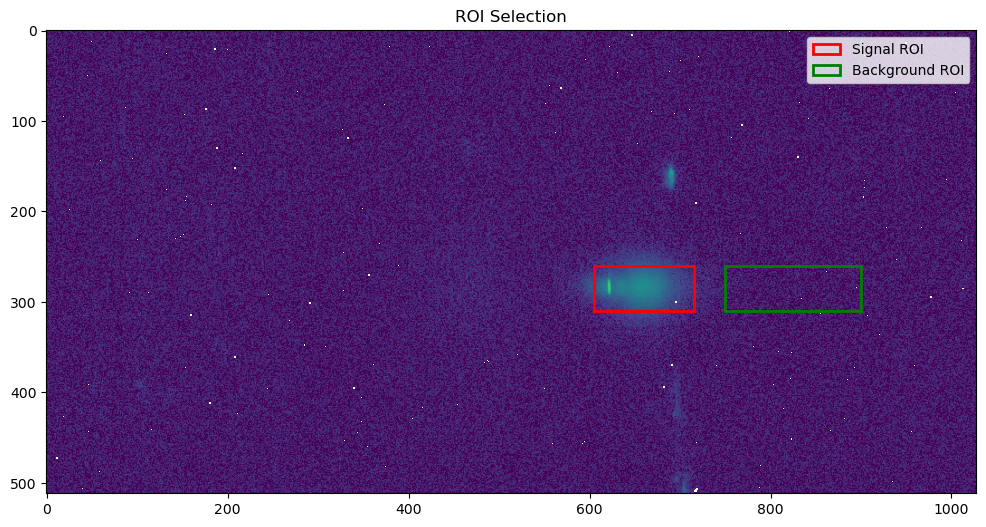

Run 802:
  G1 Com Abs: [nan, nan]
  G2 Com Abs: [nan, nan]
  G2 - G1 Com Abs: [nan, nan]
  G1 Variance: [nan, nan]
  G2 Variance: [nan, nan]
  G2 - G1 Variance: [nan, nan]
  G1 Kurtosis: [nan, nan]
  G2 Kurtosis: [nan, nan]
  G2 - G1 Kurtosis: [nan, nan]


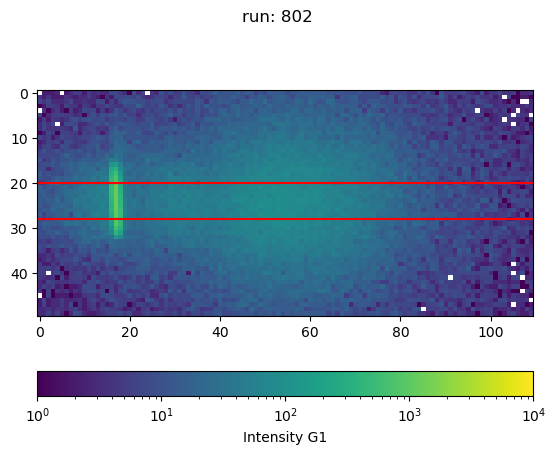

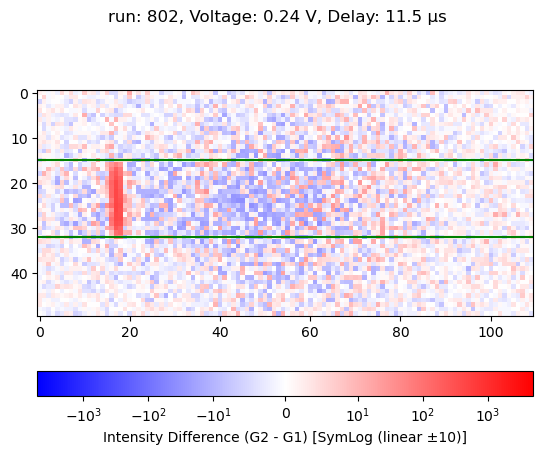

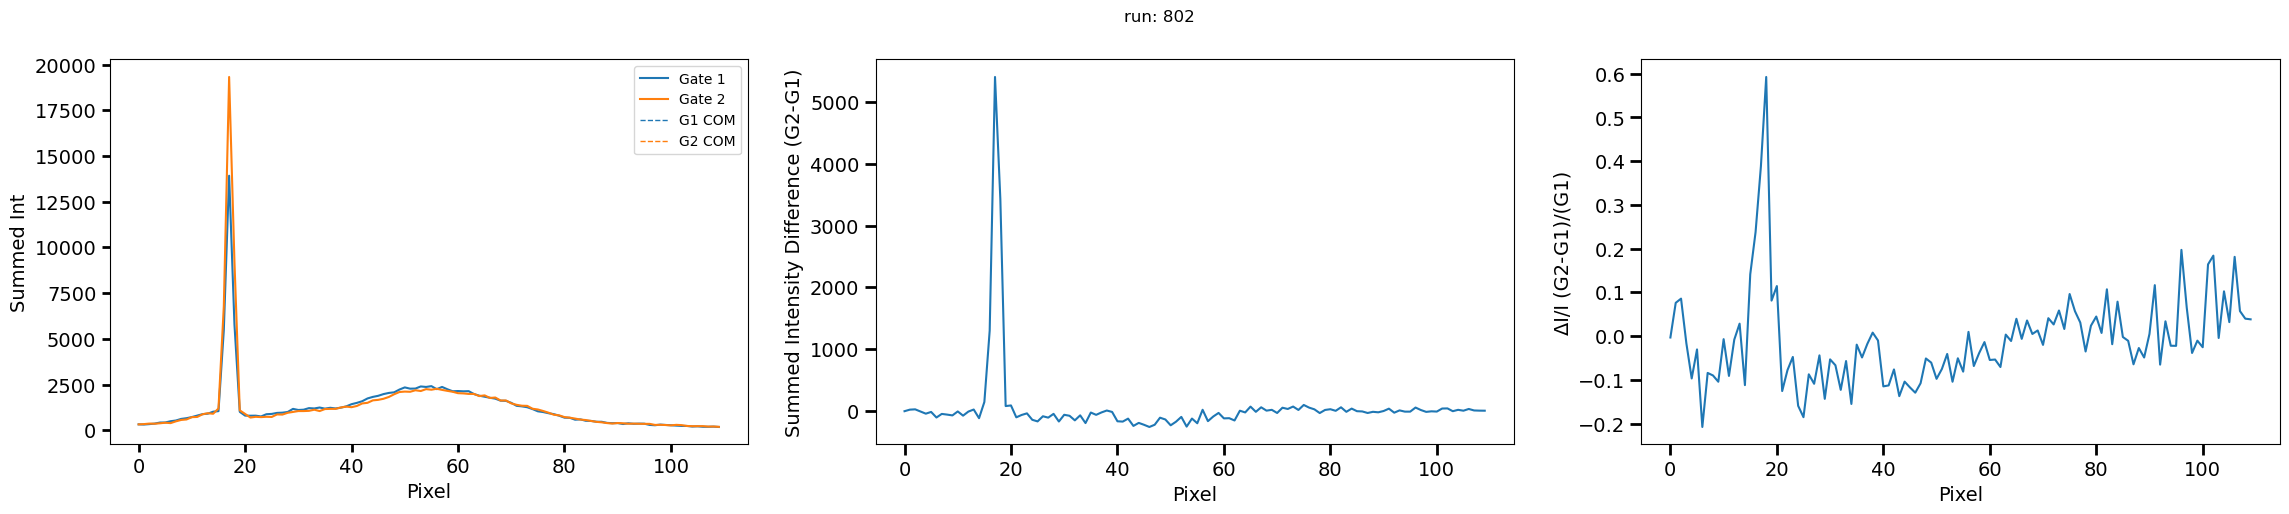

In [19]:
# 003 peak detector orientation
h5_loc = Path(r'C:\Users\leeau\Dropbox\Stanford\Lindenberg_Lab\2026_06_Lindenberg\BTO_001')
good_runs = [802]

roi = [260, 310, 605, 715]            # bto and ctr peaks
# roi = [273, 295, 619, 626]          # ctr peak only
# roi = [260, 310, 635, 690]          # bto peak ONLY
background_roi = [260, 310, 750, 900] # can play around with this, always check
lineout_range = (70, 80)

for run_num in good_runs:
    filenames = sorted(h5_loc.glob(f'run{run_num}_*_data_000001.h5'))
    print(run_num, [f.name for f in filenames])
    if not filenames:
        print(f"  no files found for run {run_num}")
        continue

    for fpath in filenames:
        info = parse_filename(fpath, fields=['run', 'voltage', 'delay', 'eta'])
        run, voltage, delay = info['run'], info['voltage'], info['delay']
        # eta = info['eta']

        with h5py.File(fpath, 'r') as h5:
            data_raw = h5['entry/data/data'][:]

        # hot pixel removal
        data = np.zeros_like(data_raw, dtype=float)
        for i in range(data_raw.shape[0]):
            # data[i] = remove_hot_pixels(data_raw[i], simple_threshold=4e5, neighbor_ratio=5)
            data[i] = remove_hot_pixels(data_raw[i])

        # visualize ROIs (first run only)
        if run_num == good_runs[0]:
            visualize_rois(data[0], roi, background_roi)

        # moments with background subtraction
        moments_g1 = calc_moments(data[0], roi, lineout_range, lineout_axis=0)
        moments_g2 = calc_moments(data[1], roi, lineout_range, lineout_axis=0)

        print_moments(moments_g1, moments_g2, keys=['background', 'com_abs', 'variance', 'kurtosis'], run=run)

        fig, ax = plot_g1_image(data, roi, moments_g1, run=run, cmap='viridis', hlines=[20, 28])

        # difference image
        fig, ax = plot_diff_image(data, roi, moments_g1, moments_g2, run=run, delay=delay, voltage=voltage,
                                  vmin=-5000, vmax=5000, show_com=False, log_scale=True, linthresh=10,
                                  hlines=[15, 32])

        # lineouts: sum over rows of the ROI (BTO and CTR)
        lineout_1 = np.nansum(data[0][roi[0]:roi[1], roi[2]:roi[3]], axis=0)
        lineout_2 = np.nansum(data[1][roi[0]:roi[1], roi[2]:roi[3]], axis=0)

        fig, ax = plot_lineouts(lineout_1, lineout_2, moments_g1, moments_g2, run=run,
                                eta=None, figsize=(28, 5), show_com=True)

In [20]:
#define ROI's of interest based on the code block above
both_roi_smaller = [260, 310, 605, 715] # bto and ctr peaks
#column values = 33,63,83
#lineout values = 15,32
bto_roi_smaller = [260, 310, 635, 690] #bto peak only
#column values = 3,33,53
#lineout_values = 15,32
ctr_roi_smaller = [273, 295, 619, 626] #ctr peak only
#column values = 2,4,6 or 2,5,7
#lineout_values = 2,20
background_roi_smaller = [260,310, 750, 900]
exclude_ctr_smaller = (619,626)

In [24]:
h5_loc=Path(r'C:\Users\leeau\Dropbox\Stanford\Lindenberg_Lab\2026_06_Lindenberg\BTO_001')
run_range = (751,767) # Voltage Ramp 0 V to peak positive

#time delay scan locations
# run_range=list(range(768, 770)) + list(range(771,781)) + [805]   #768, 782 # h5_loc, 3 kHz triangle
# run_range = (783,793) #l5_loc, 3.03 kHz PUND, 0 V before first negative, sweep through negativse
# run_range = (794,802) # #h5_loc, 3.03 kHz PUND, 0 V before first negative, fine scan along first negative.

In [25]:
roi = both_roi_smaller
roi_name = 'both_roi_smaller'
# lineout_range = (0, both_roi_smaller[1] - both_roi_smaller[0]) # full roi
lineout_range = (15,32) # focused lineout

Found 17 files to process
Processing run 751...
Processing run 752...
Processing run 753...
Processing run 754...
Processing run 755...
Processing run 756...
Processing run 757...
Processing run 758...
Processing run 759...
Processing run 760...
Processing run 761...
Processing run 762...
Processing run 763...
Processing run 764...
Processing run 765...
Processing run 766...
Processing run 767...

Processed 17 runs successfully!


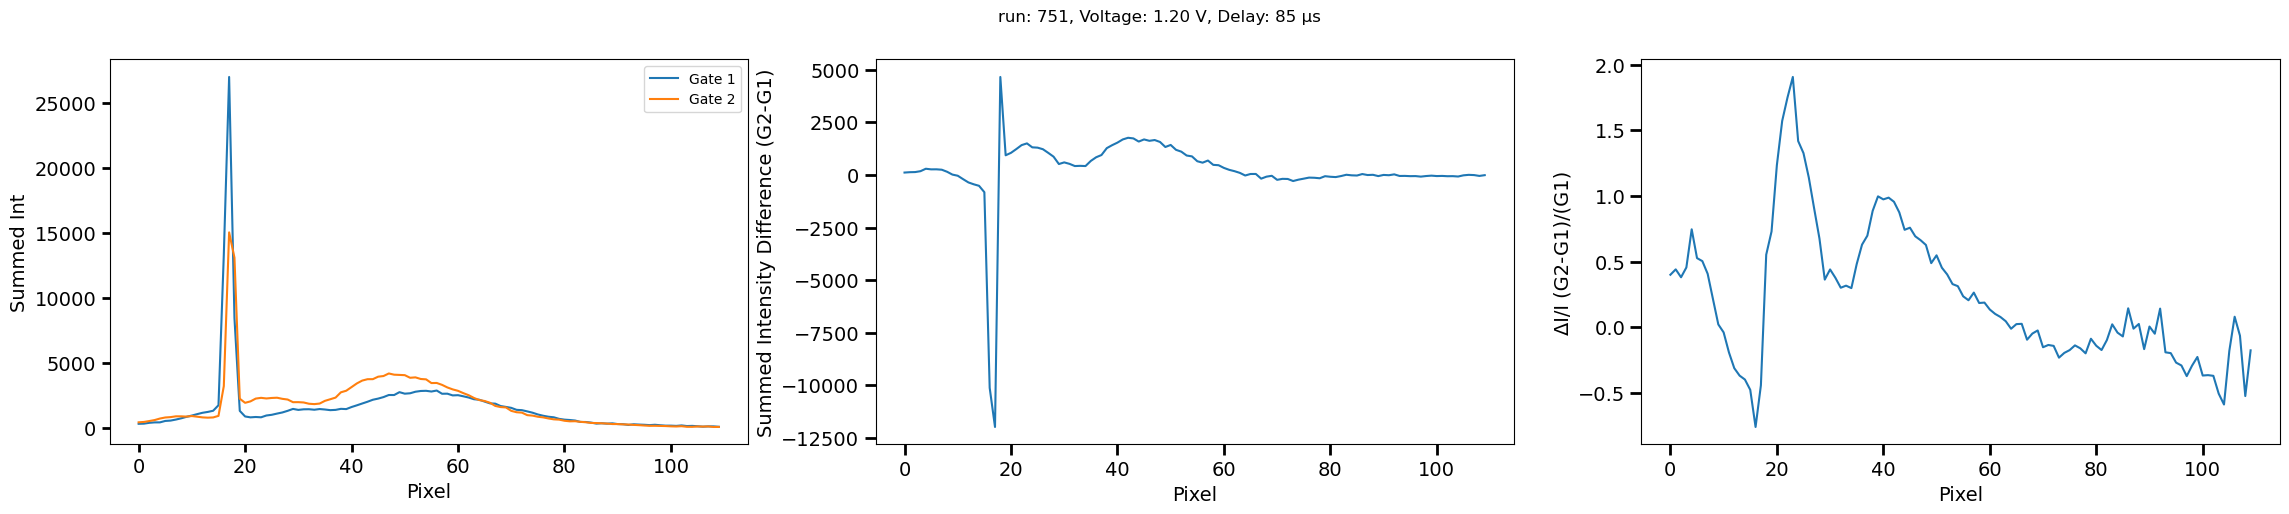

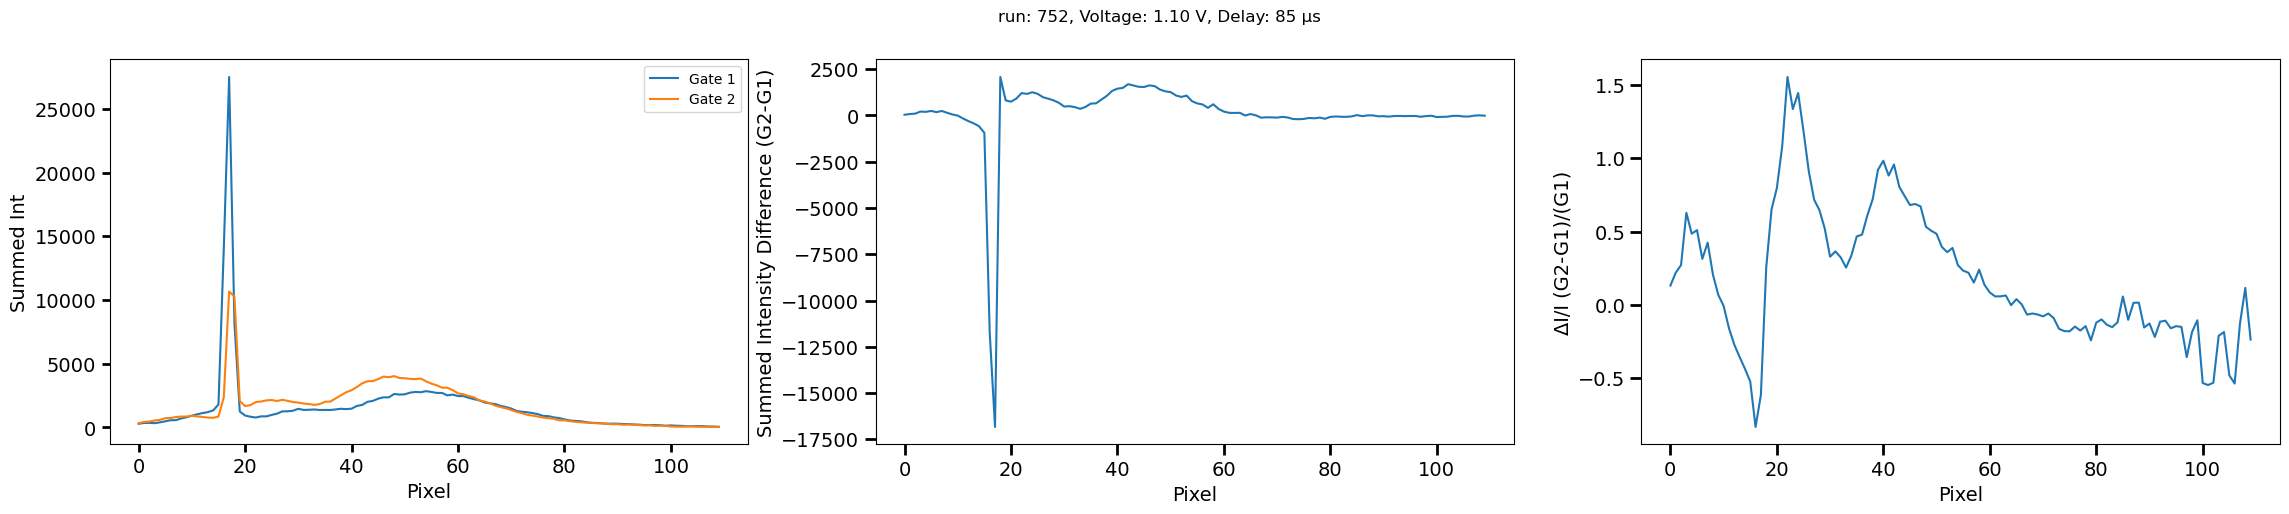

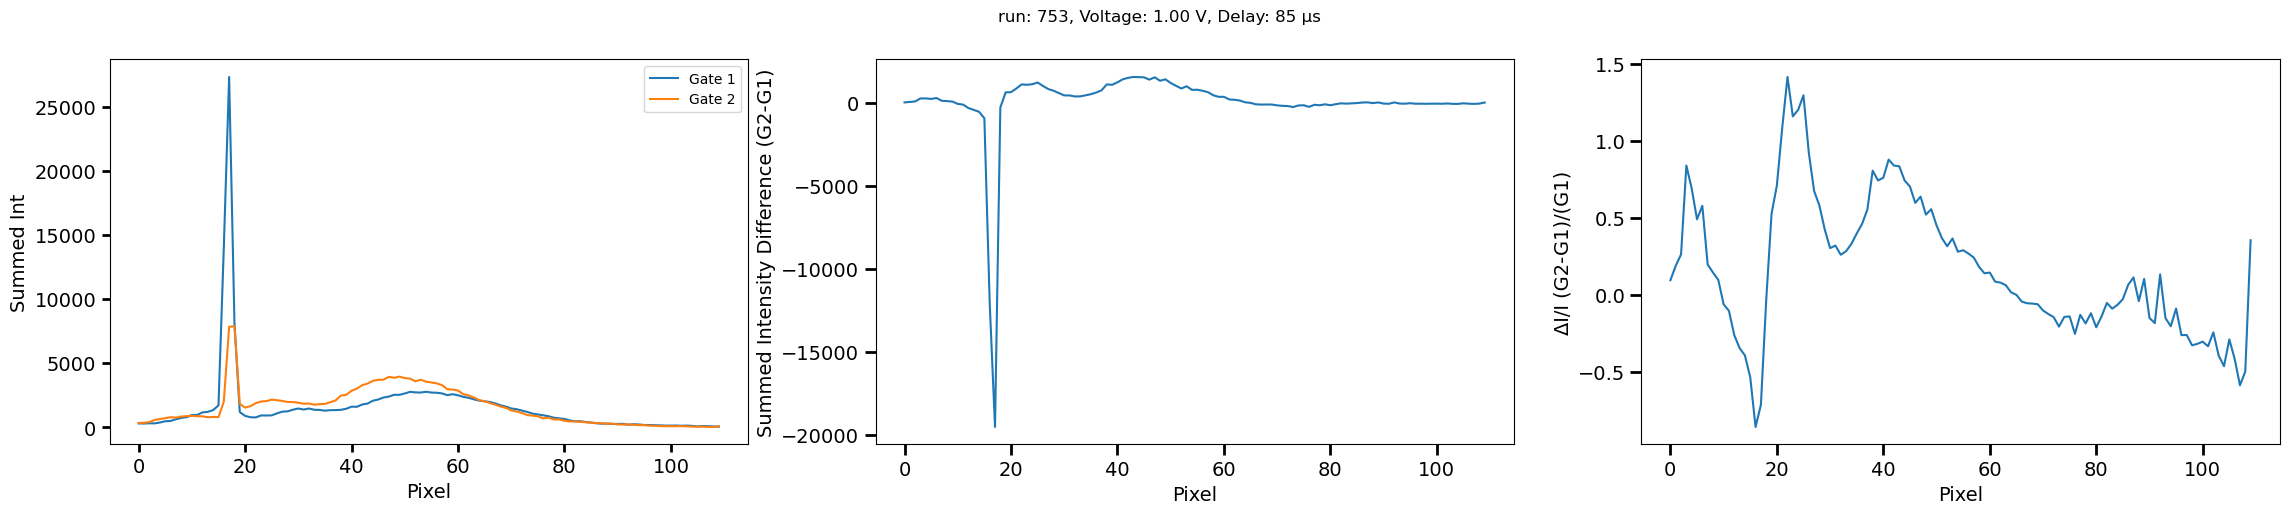

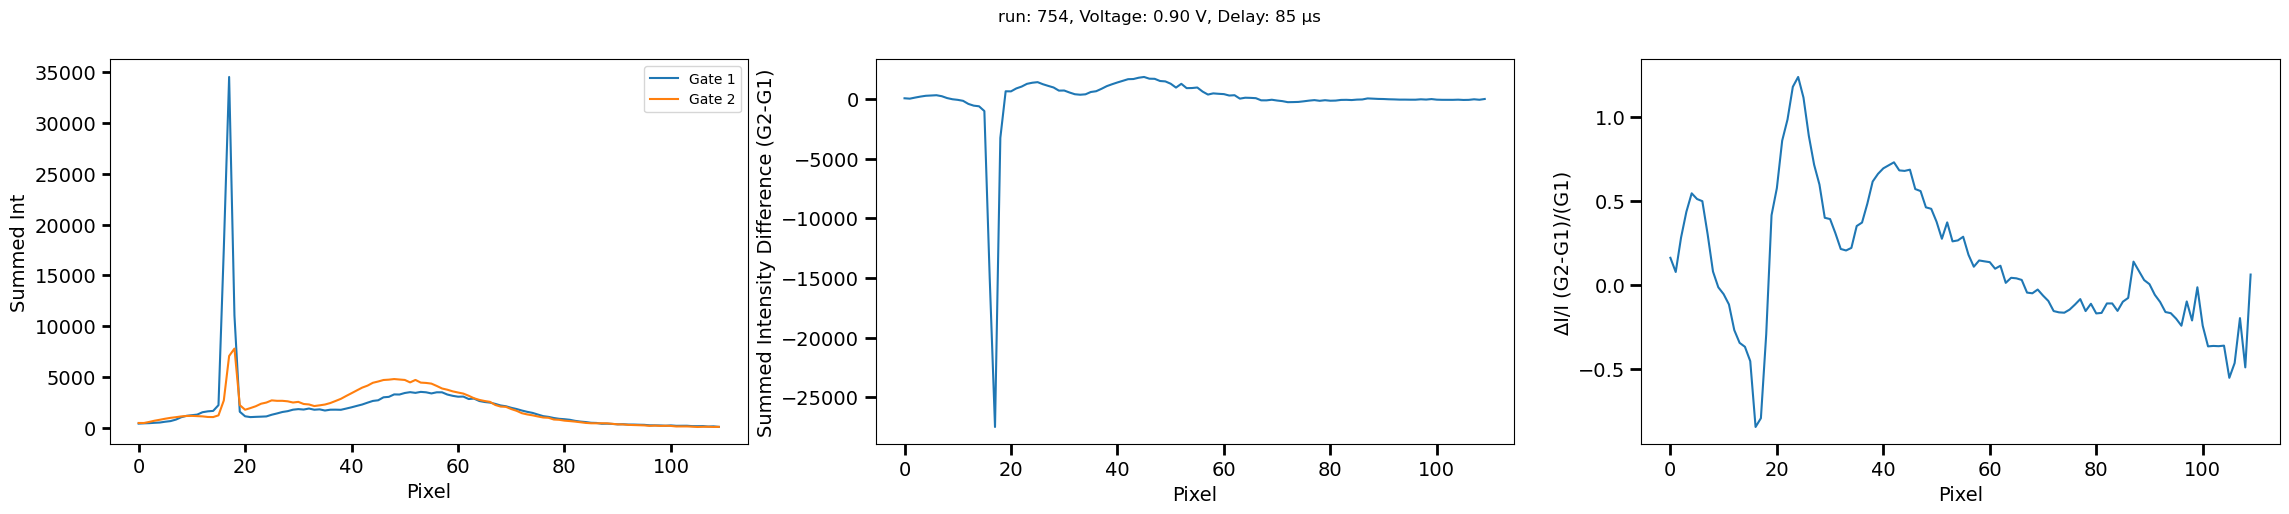

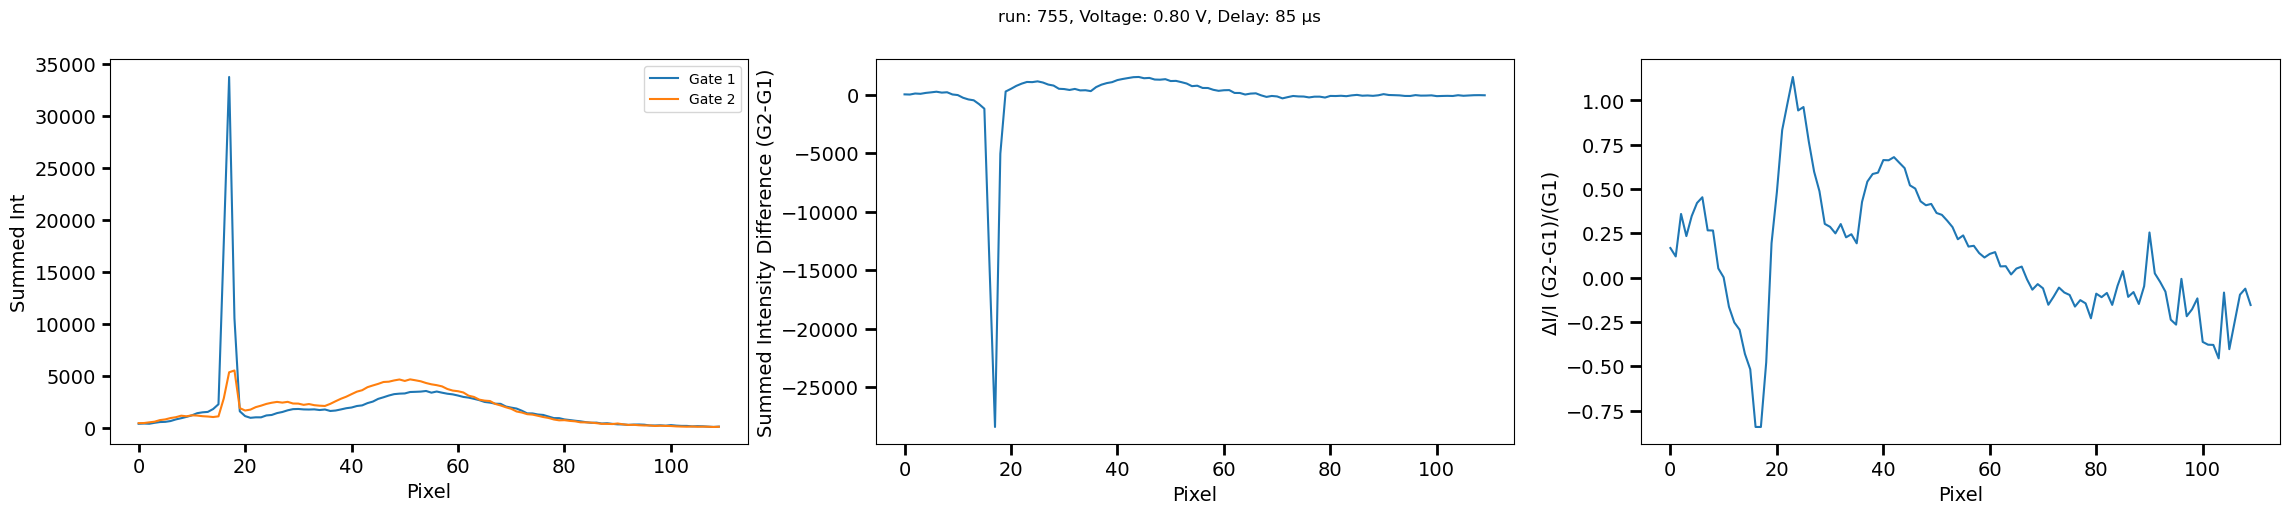

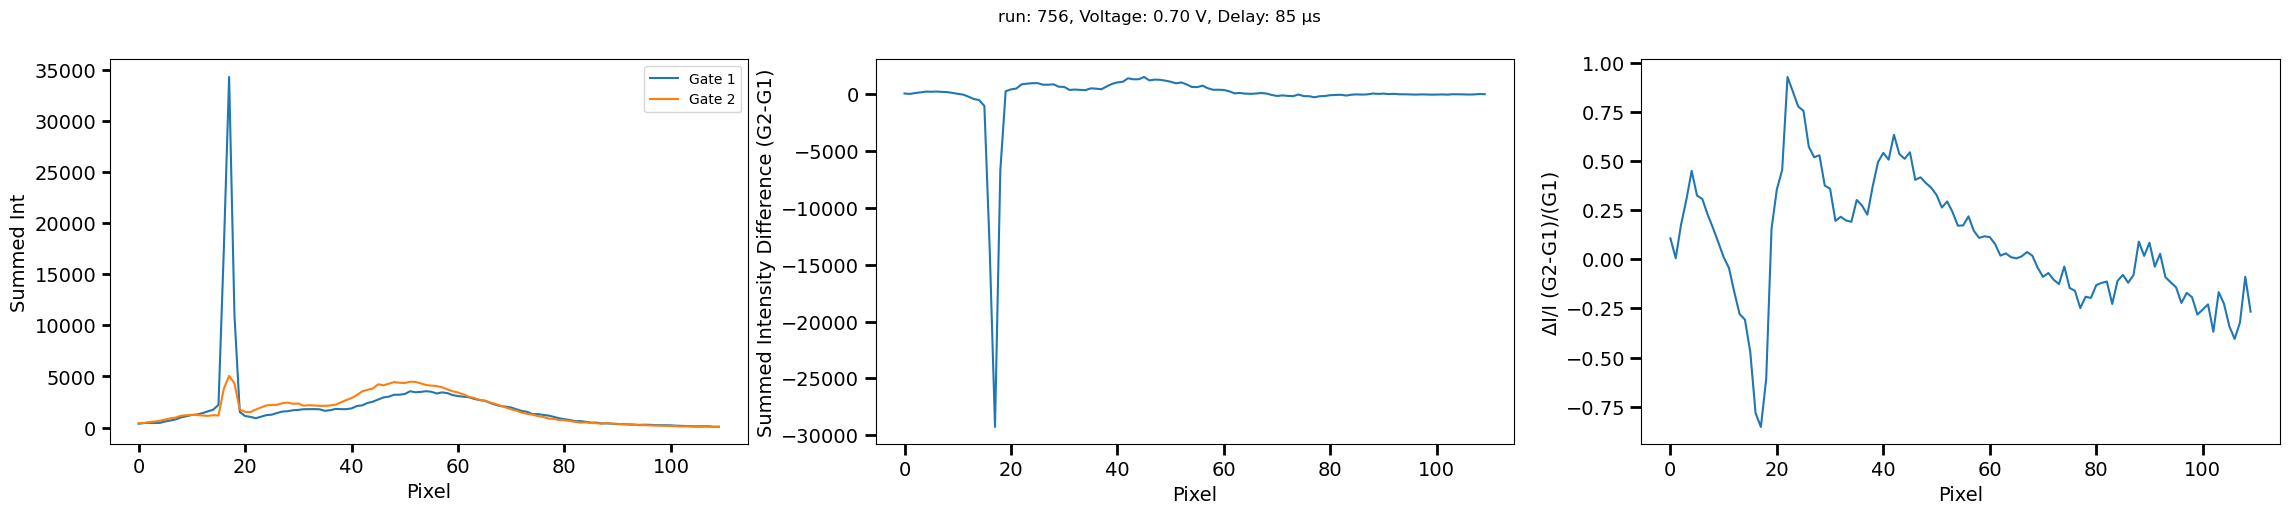

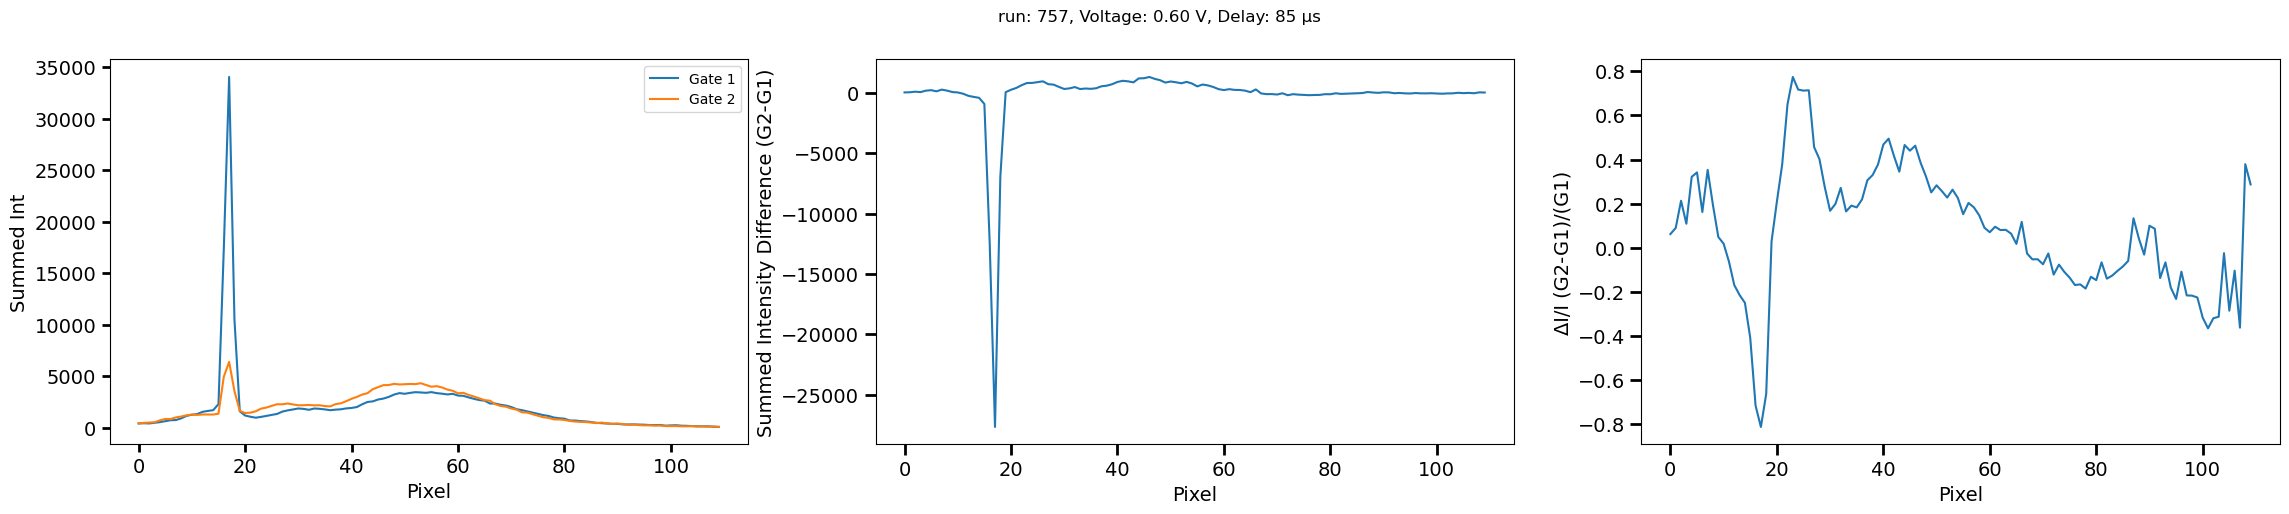

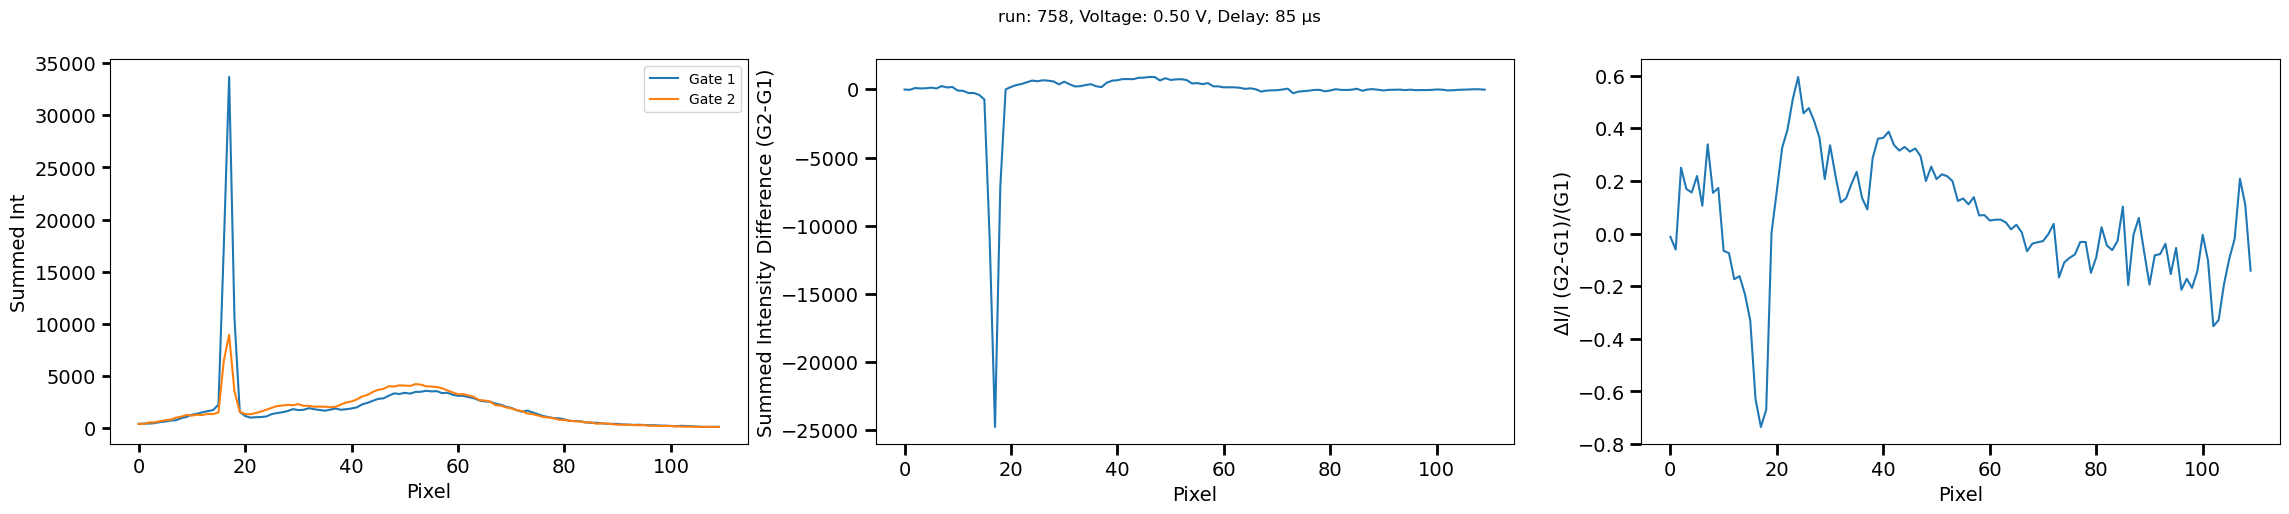

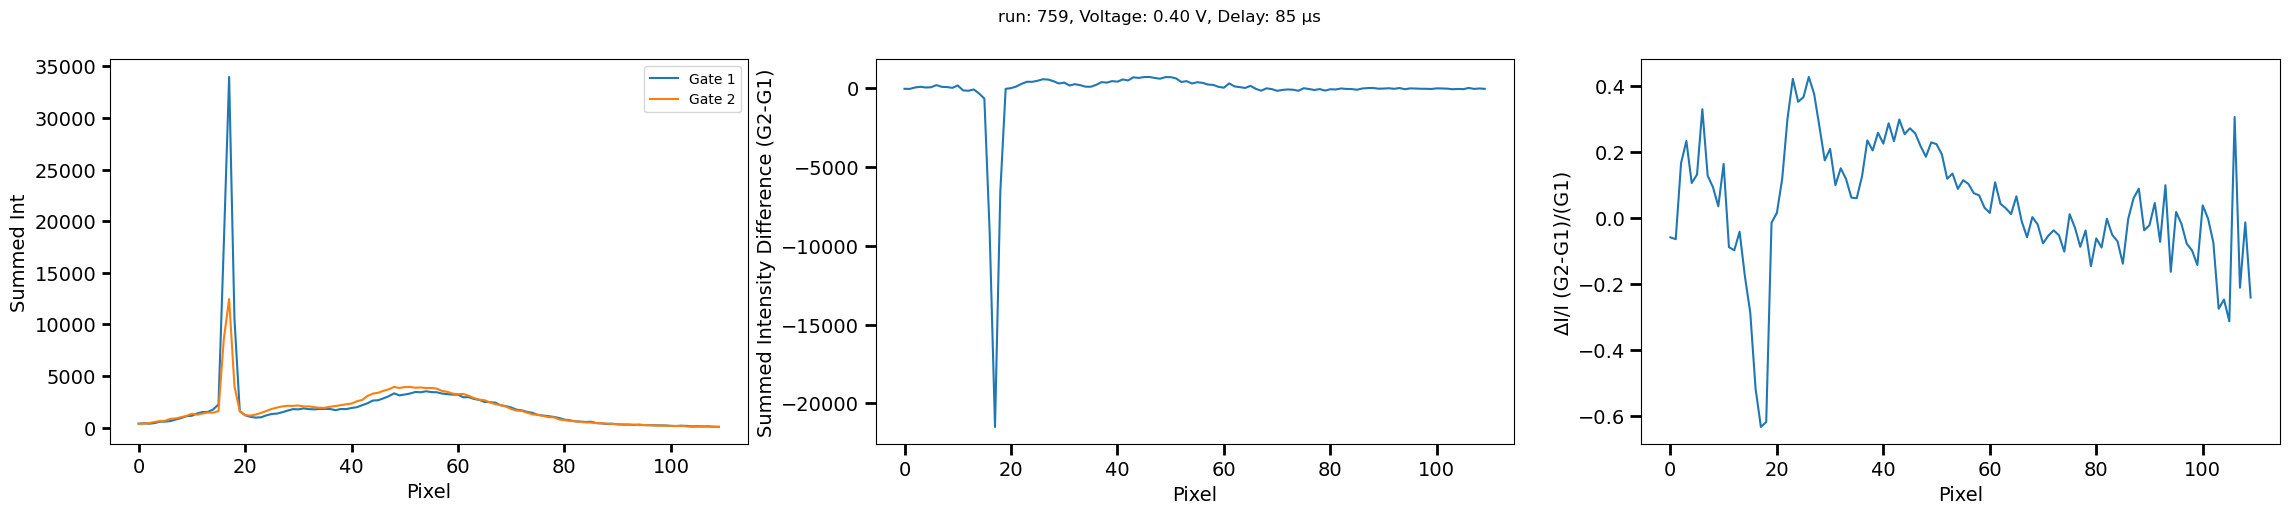

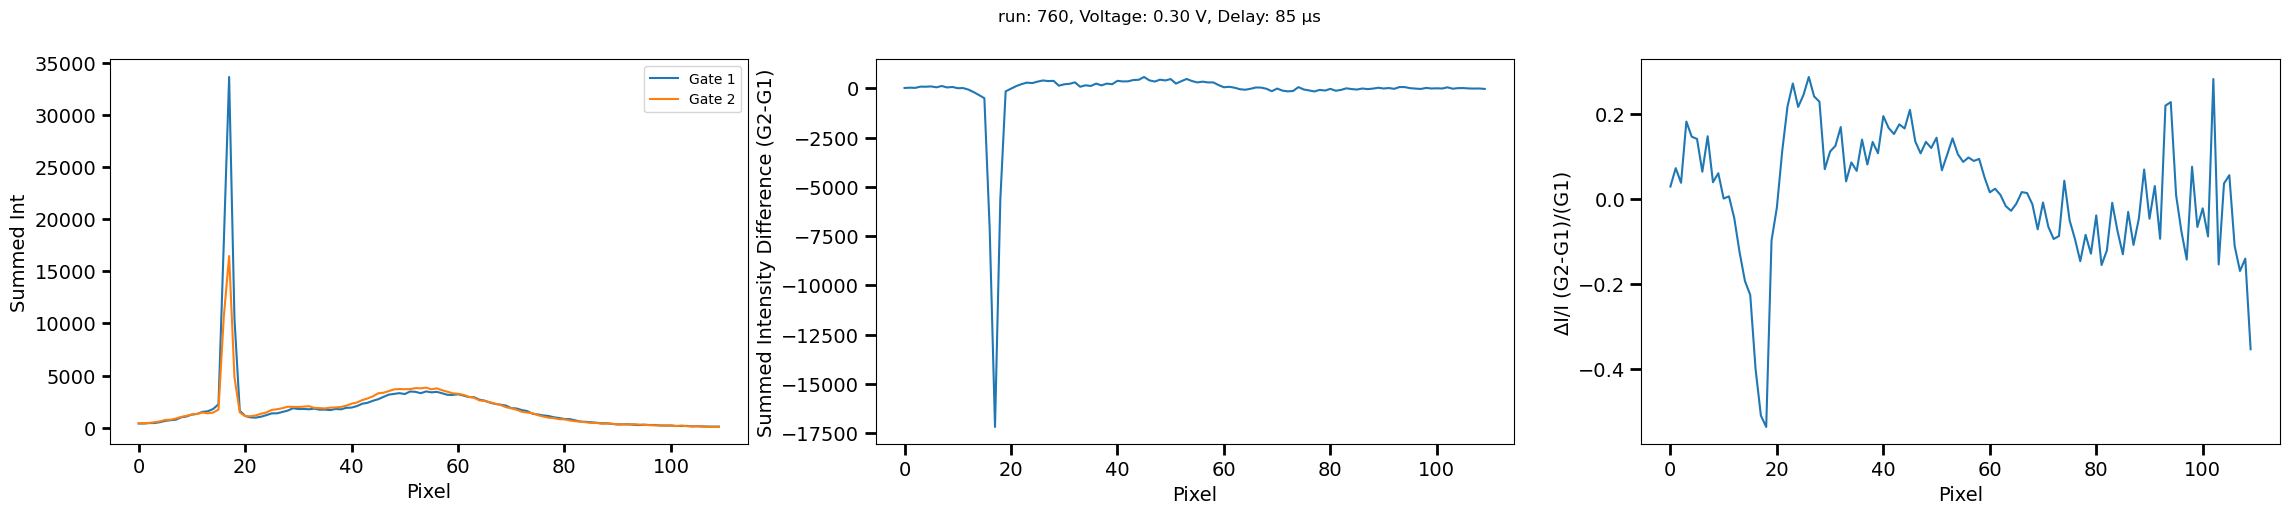

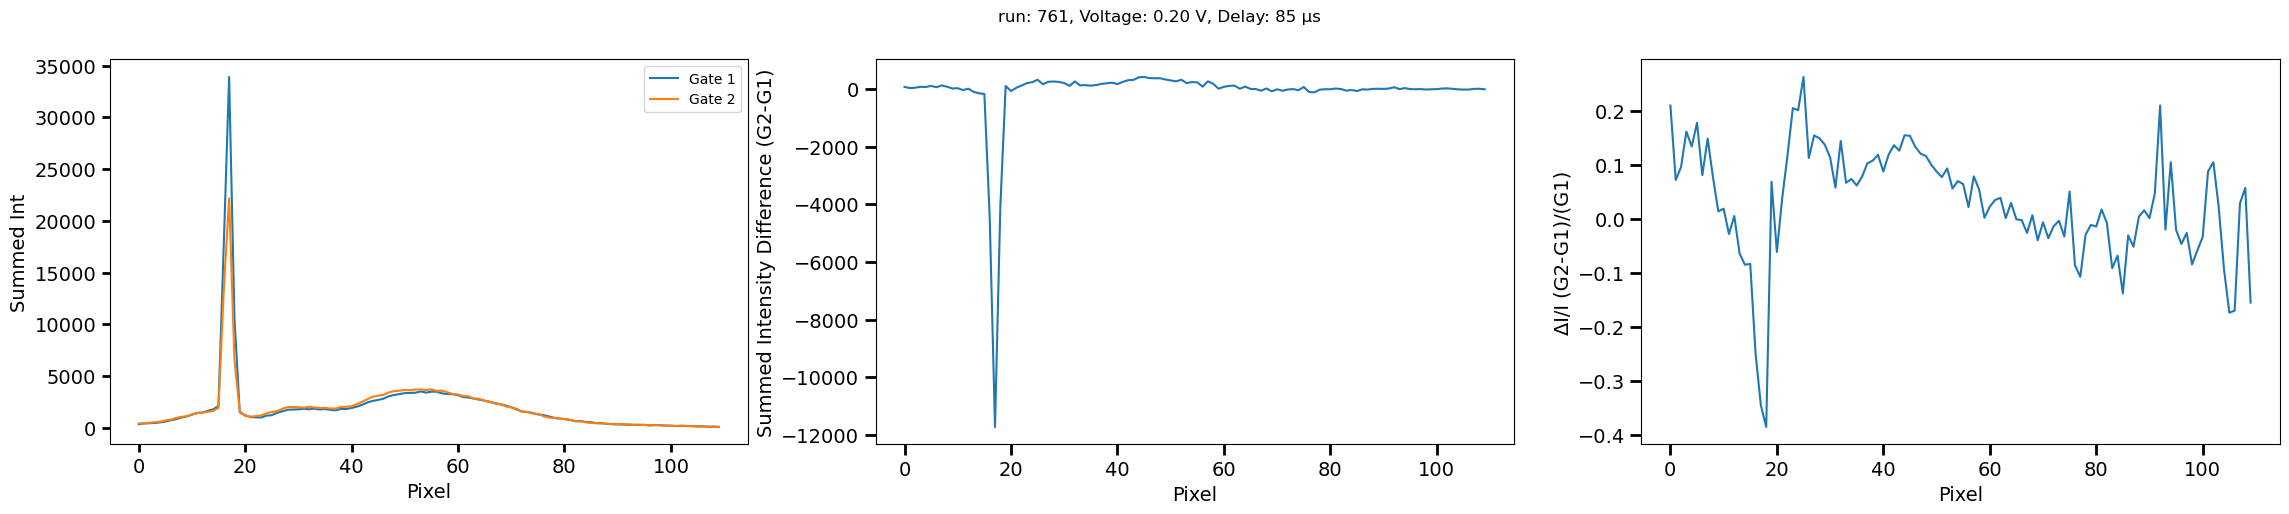

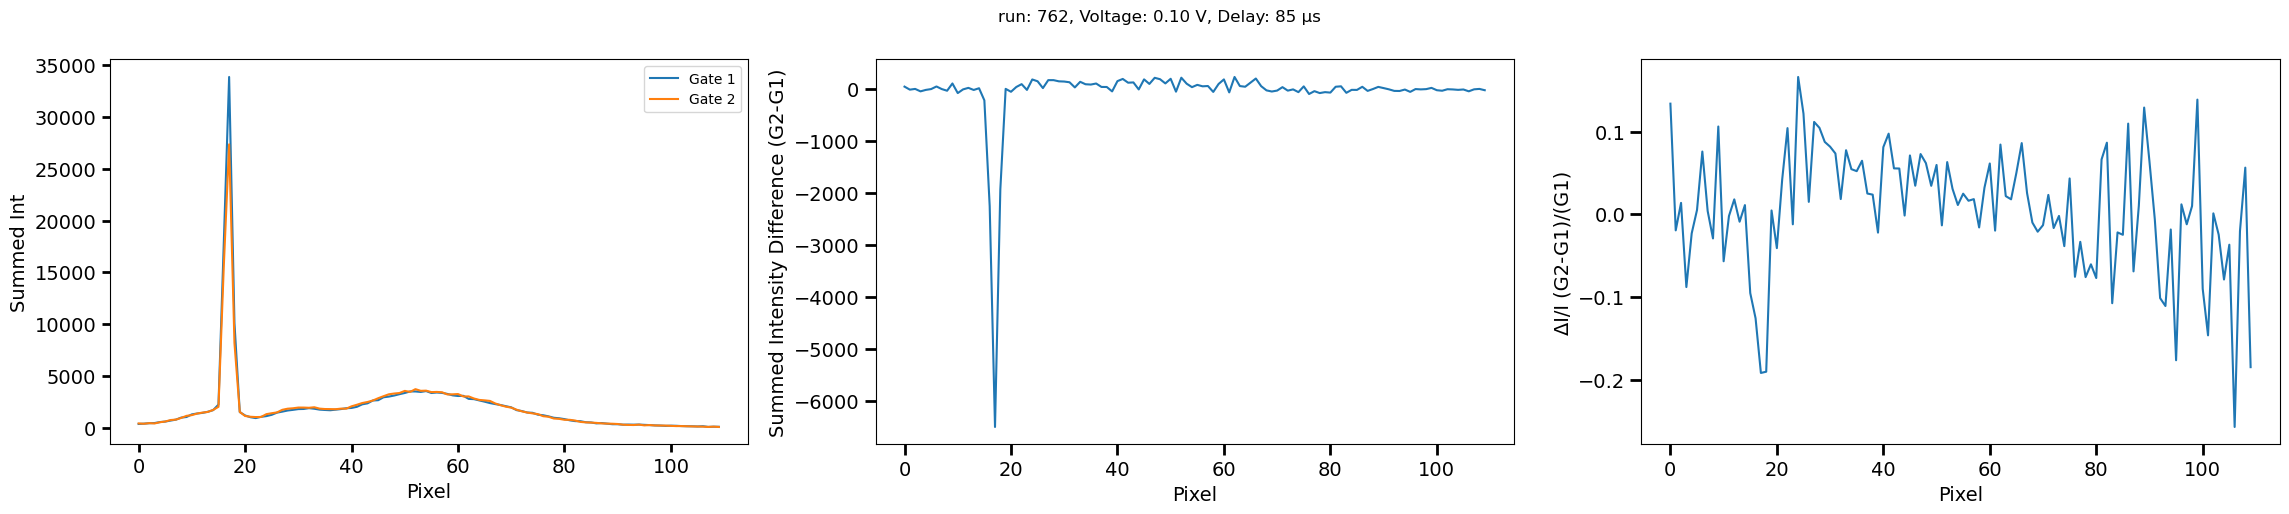

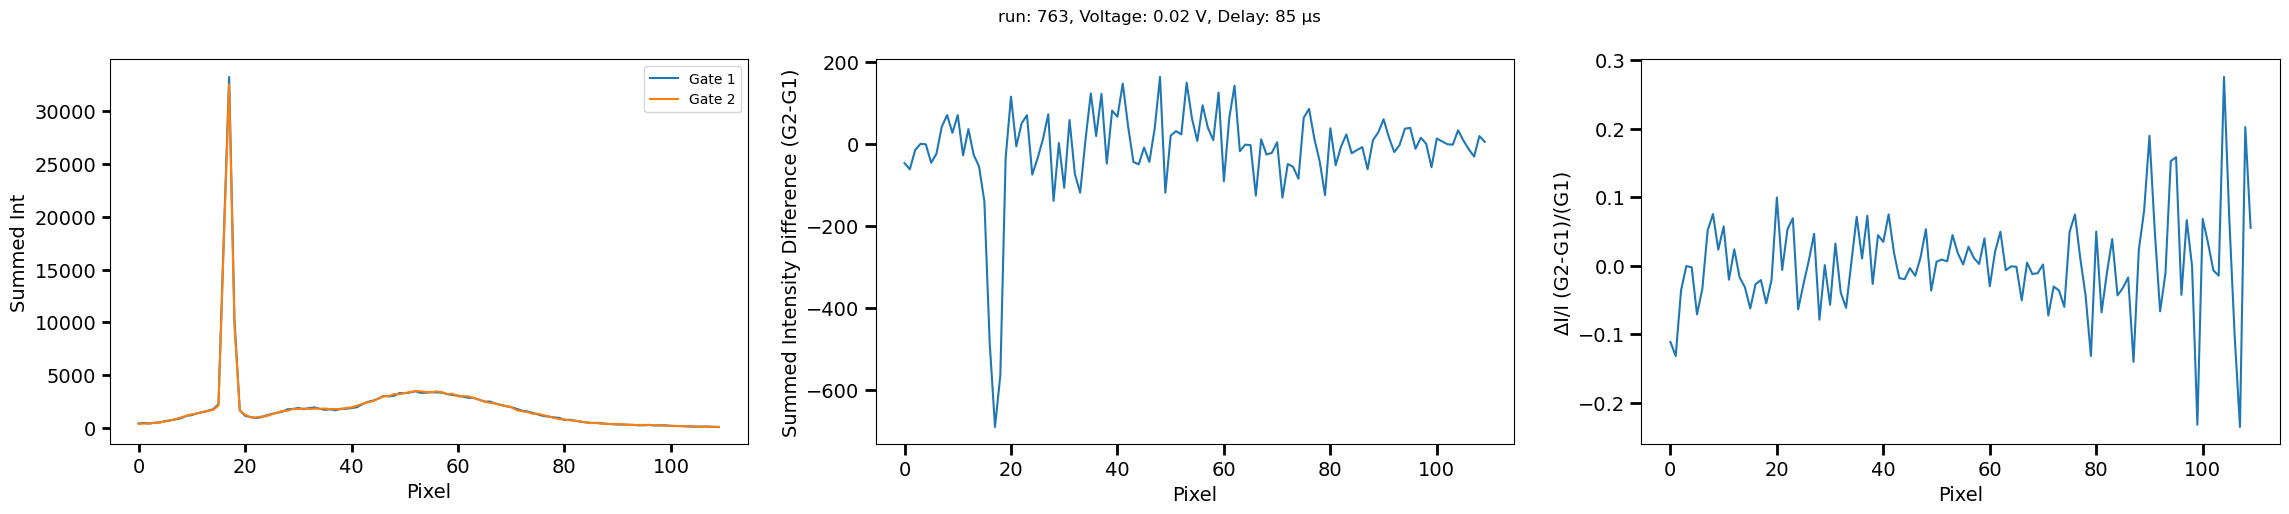

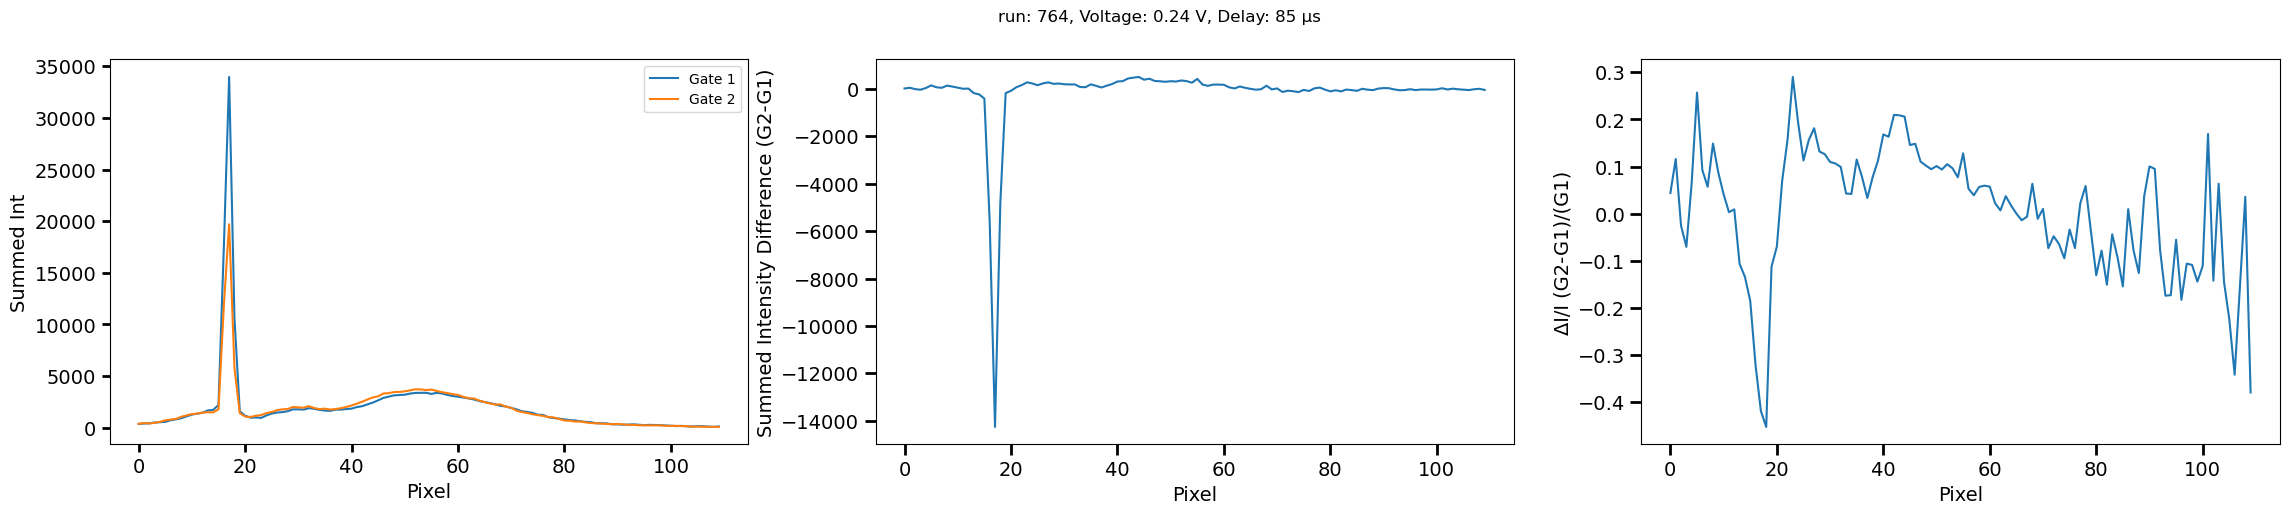

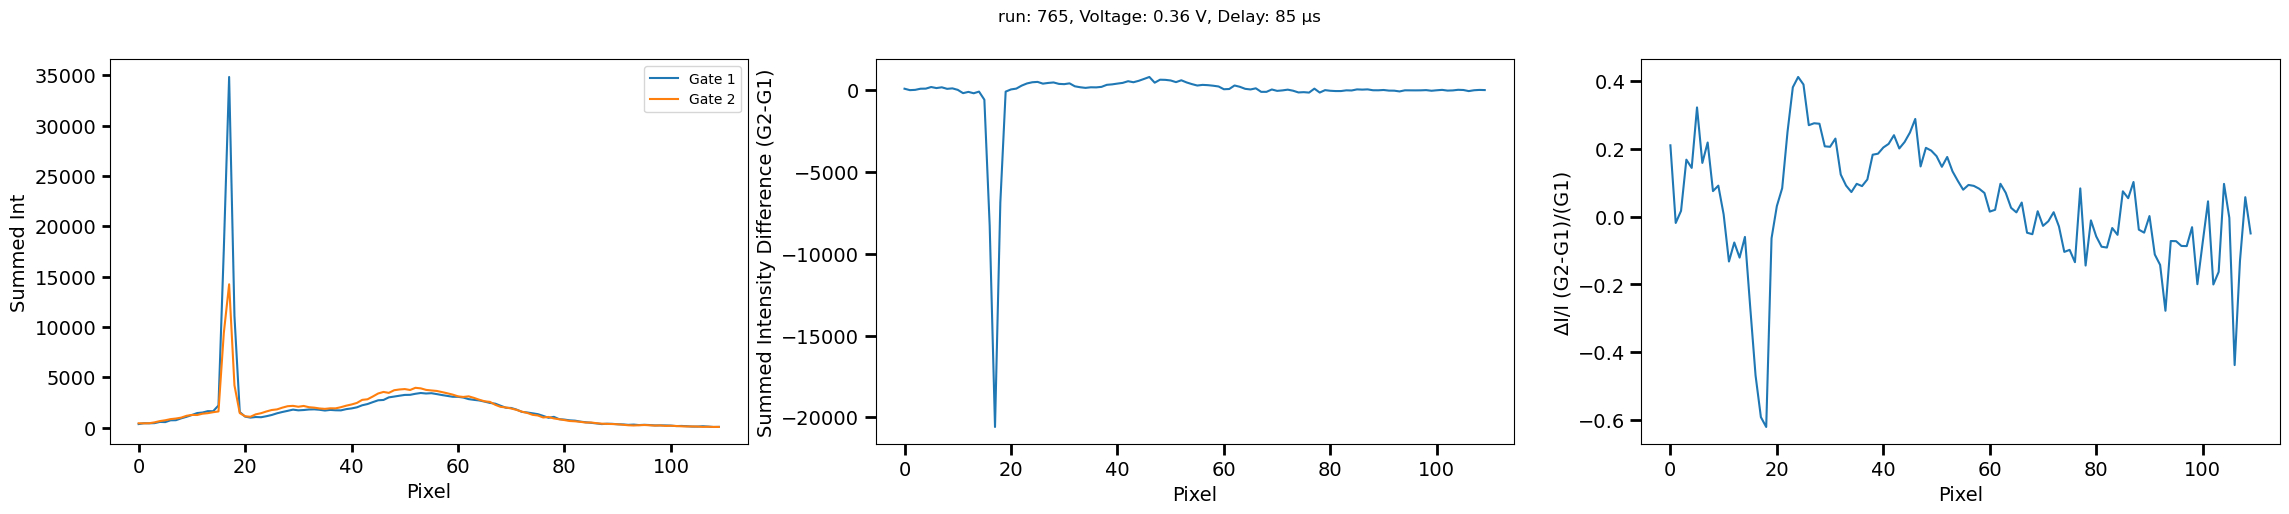

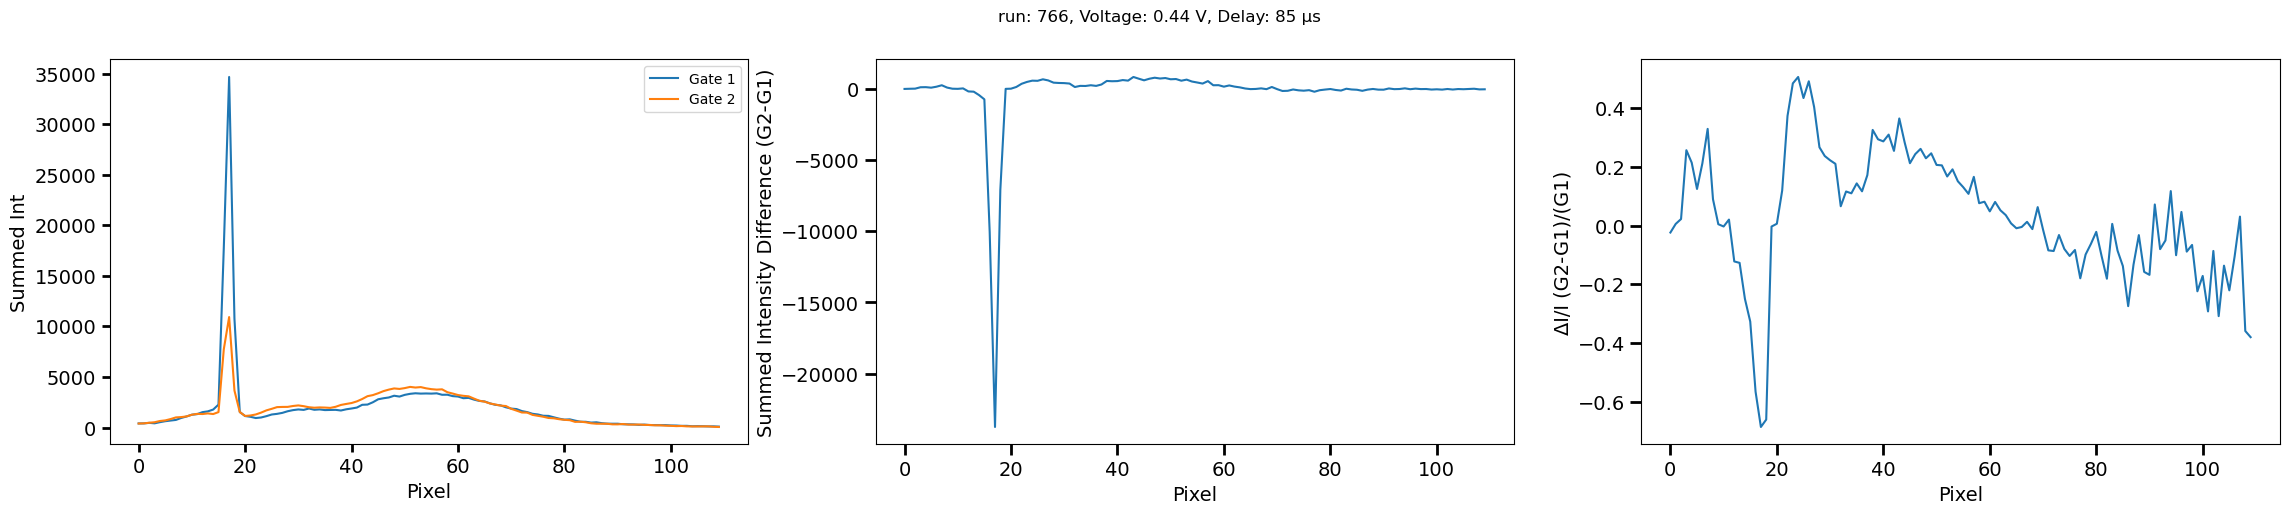

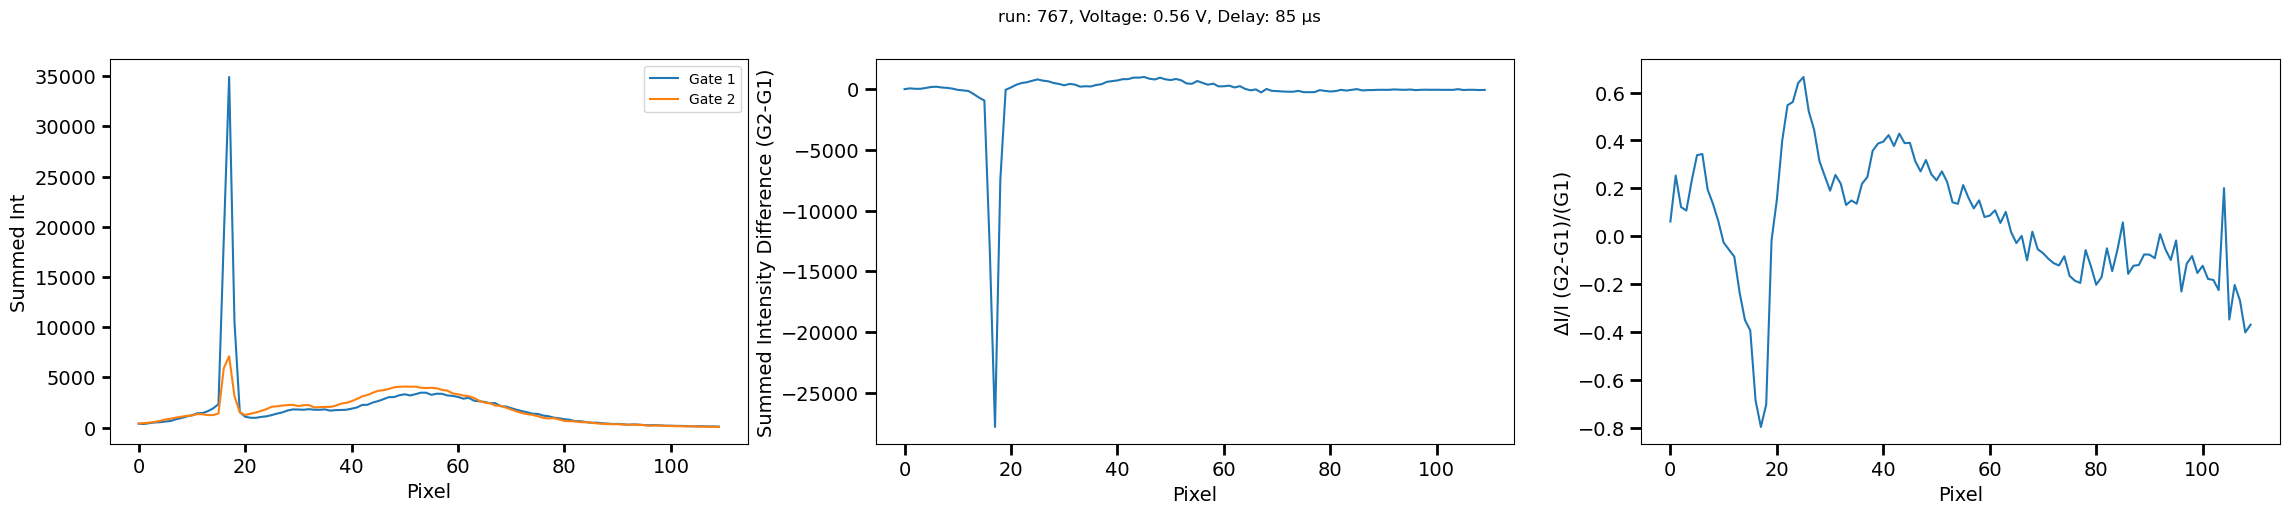

In [26]:
# VOLTAGE RAMP SCANS 355-367; CTR PEAK ONLY, small roi
results = process_scan_data(
    h5_loc=h5_loc,
    roi=roi,
    background_roi = background_roi_smaller,
    run_range=run_range, #voltage ramp = 355-367 220 peak 
    lineout_range = lineout_range, # to sum over the entire ROI, BTO and Both roi smaller
    peak_diff_col_ranges=((33,63), (63,83)), #column values for both_roi
    plot_diff_image_flag = False, #if true or commented out the difference plots will show 
    plot_lineouts_flag = True,
    show_com_on_diff_image = False,
    show_com_on_lineouts=False,
    diff_image_kwargs = {'vmin': -5000, 'vmax': 5000, 'log_scale': True, 'linthresh': 10}
)

In [ ]:
# # #Access results
# voltage_list = list(results['voltage_dict'].values())
# delay_list = list(results['delay_dict'].values())
# peak_diff_list = list(results['peak_diff_dict'].values())
# intensity_g1_list = list(results['intensities_g1'].values())
# intensity_g2_list = list(results['intensities_g2'].values())
# com_1_list = np.array(list(results['com_g1'].values()))
# com_2_list = np.array(list(results['com_g2'].values()))  

In [27]:
animate_diff_images(
    results,
    # x_param = 'voltage',
    x_param='delay',
    roi=roi,
    # xlim = (500, 675),
    vmin=-10000,
    vmax=10000,
    show_gate_images = True,
    vmin_gate = 1,
    vmax_gate = 1e4,
    show_com=False,
    interval=500,
    # save_path = save_path / f'bto001_peak003_{roi_name}_voltage_scan_{run_range[0]}_{run_range[1]}_10kHz_triangle_difference_animation_logscale.mp4',
    save_path = save_path / f'bto001_peak003_{roi_name}_delay_scan_{run_range[0]}_{run_range[1]}_10kHz_triangle_difference_animation_logscale.mp4',
    log_scale = True,
    linthresh = 10
)

Creating animation for delay range [85.0, 85.0] with 17 runs...
  Using SymLog (linear ±10) color scale

=== Animation Delay Range: 85.0 to 85.0 ===


[<IPython.core.display.HTML object>]